# Regularization on a small-data MNIST-1D problem

An unregularized MLP (two hidden layers of 256 units, 79k parameters) trained on 1000 MNIST-1D examples reaches 100% train accuracy and 45.8% validation accuracy. I attack that gap with one method at a time (L2, early stopping, dropout written from scratch, ensembles and bagging, data augmentation, label smoothing) and add each method's best model to a shared leaderboard. Where the true function is needed, to measure bias and variance or to see what λ and early stopping do to a fitted curve, I use a 1D toy regression on noisy samples of $\sin(2\pi x)$. The last sections look at two things the classical picture misses: the implicit regularization of small batches, and double descent.

**Results**

- Measured over 200 datasets, the best capacity of a piecewise-linear model is 4 regions with 15 training points and 5–6 regions with 100. With 15 points the variance explodes to 2.37 at 14 regions and falls again past the interpolation point.
- Validation accuracy on the leaderboard: augmentation 0.642, dropout (keep 0.5) 0.537, L2 (λ = $10^{-3}$) 0.514, 10-seed ensemble 0.494, label smoothing 0.480, early stopping 0.465, bagging 0.461, baseline 0.458. On the test set, measured once, augmentation and dropout are also the top two.
- L2 mostly fixes the loss: it halves the validation loss (4.08 → 2.03) and adds 5.6 points of accuracy, because the unregularized network is confidently wrong on half the validation set.
- My NumPy dropout backward pass matches finite differences ($9\cdot10^{-7}$) and autograd. Monte-Carlo dropout matches weight scaling in accuracy from $T \approx 20$ passes and gives a lower NLL (1.39 against 1.85 at $T = 200$).
- Label smoothing barely moves the accuracy but cuts the calibration error (ECE) from 0.42 to 0.036. Augmentation does the opposite: +18 points of accuracy, with the ECE still at 0.145.
- At an equal number of updates, batch size 8 gets 3 points more validation accuracy than full-batch GD. With 20% label noise, the validation error peaks at the interpolation threshold (width 96, 4906 parameters for 3000 examples) and falls again for wider networks.
- With only 500 training examples, a small 1D CNN with augmentation, dropout, light L2 and a 5-seed ensemble reaches 83.8% test accuracy. The unregularized MLP gets 36% on validation.

**Environment:** PyTorch on a CPU, about 10 minutes for the whole notebook. The first cell installs `mnist1d` if it is missing.

## Contents

| Section | Topic |
|---|---|
| 0 | Setup, data, and the baseline to fix |
| 1 | The bias–variance trade-off, measured |
| 2 | L2 regularization and weight decay |
| 3 | Early stopping |
| 4 | Dropout from scratch (NumPy and PyTorch) |
| 5 | Ensembles and bagging |
| 6 | Noise on the inputs (augmentation) and on the labels (label smoothing) |
| 7 | Implicit regularization of SGD, and double descent |
| 8 | Combining everything on 500 examples |

Two kinds of checks follow the code. `assert` tests check an implementation on small controlled inputs. `expect(...)` lines print ✓ or ⚠ depending on whether an experimental result looks as expected. Hyperparameters are always chosen on the validation set. The test set is used once, in the leaderboard at the end.

---
## 0. Setup

The data, the models, the training loop and the plotting helpers used by every later section.

In [1]:
import importlib.util, subprocess, sys

if importlib.util.find_spec("mnist1d") is None:  # MNIST-1D dataset generator (Greydanus, 2020)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "mnist1d"])

import copy, functools, math, os, random, time, warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from mnist1d.data import get_dataset_args, make_dataset

warnings.filterwarnings("ignore", message=".*smallest subnormal.*")
torch.set_num_threads(min(4, os.cpu_count() or 1))
torch.set_flush_denormal(True)  # tiny weights (strong regularization) are otherwise very slow on CPU
plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3})


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


SEED = 0
seed_everything(SEED)
print("torch", torch.__version__)

torch 2.15.0+cpu


### 0.1 Dataset A — a 1D toy regression problem

The same kind of problem used in the lecture figures (Prince, *Understanding Deep Learning*):
a few noisy samples of $f(x) = \sin(2\pi x)$ on $[0, 1]$. Because we know the true function, we can measure
the **true generalization error** exactly: `toy_test_mse(model)` compares the model with $f$ on a dense grid.

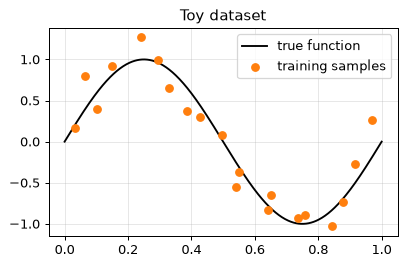

In [2]:
def true_fn(x):
    return np.sin(2 * np.pi * x)


def make_toy_data(n, noise_std=0.3, seed=0):
    """n noisy samples of true_fn; x is stratified on [0, 1] so the points cover the interval."""
    rng = np.random.default_rng(seed)
    x = (np.arange(n) + rng.uniform(size=n)) / n
    y = true_fn(x) + noise_std * rng.standard_normal(n)
    return (torch.tensor(x, dtype=torch.float32)[:, None],
            torch.tensor(y, dtype=torch.float32)[:, None])


X_GRID = torch.linspace(0, 1, 500)[:, None]
Y_GRID_TRUE = torch.tensor(true_fn(X_GRID.numpy()), dtype=torch.float32)


@torch.no_grad()
def toy_test_mse(model):
    """MSE between the model and the *true* function on a dense grid (= true generalization error)."""
    model.eval()
    return F.mse_loss(model(X_GRID), Y_GRID_TRUE).item()


X_TOY, Y_TOY = make_toy_data(20, noise_std=0.3, seed=SEED)

plt.figure(figsize=(5, 3))
plt.plot(X_GRID, Y_GRID_TRUE, "k", label="true function")
plt.scatter(X_TOY, Y_TOY, c="C1", zorder=3, label="training samples")
plt.legend(); plt.title("Toy dataset"); plt.show()

### 0.2 Dataset B — MNIST-1D (classification)

[MNIST-1D](https://github.com/greydanus/mnist1d) is a 1D analogue of MNIST: each example is a length-40
signal made from one of 10 digit-like templates, then randomly shifted, scaled, sheared and corrupted with
noise. It is the dataset used in the lecture's *SGD: Generalization* and *Double descent* slides. It is
small enough to train dozens of models on a CPU, yet hard enough that an MLP overfits badly.

We use a **small-data regime**: 1000 training examples, 1000 validation examples, and the official
1000 test examples. `label_noise` (used in Section 7) replaces a fraction of the *training* labels with random ones.

{'X_train': (1000, 40), 'y_train': (1000,), 'X_val': (1000, 40), 'y_val': (1000,), 'X_test': (1000, 40), 'y_test': (1000,)}


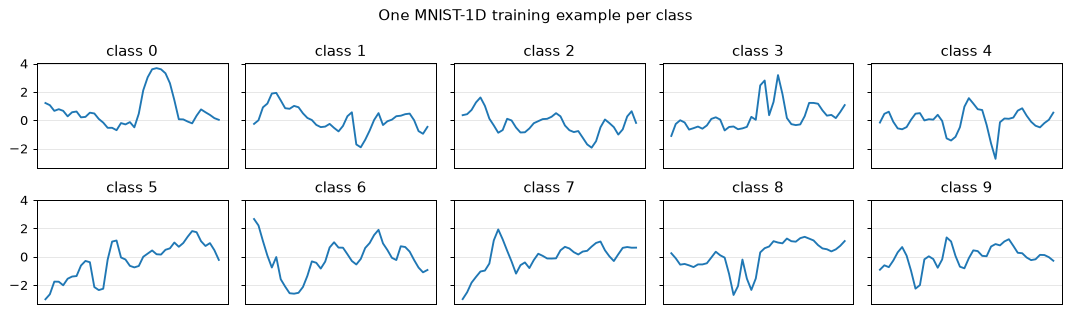

In [3]:
@functools.lru_cache(maxsize=1)
def _mnist1d_raw():
    data = make_dataset(get_dataset_args())  # 4000 train-pool + 1000 test examples, fixed generator seed
    return data["x"].astype(np.float32), data["y"], data["x_test"].astype(np.float32), data["y_test"]


def load_mnist1d(n_train=1000, n_val=1000, label_noise=0.0, seed=0):
    x, y, x_test, y_test = _mnist1d_raw()
    rng = np.random.default_rng(seed)
    perm = rng.permutation(len(y))
    val_idx, tr_idx = perm[:n_val], perm[n_val:n_val + n_train]
    y_train = y[tr_idx].copy()
    if label_noise > 0:
        flip = rng.random(len(y_train)) < label_noise
        y_train[flip] = rng.integers(0, 10, flip.sum())  # uniformly resampled label
    t = lambda a, dt=torch.float32: torch.tensor(a, dtype=dt)
    return dict(X_train=t(x[tr_idx]), y_train=t(y_train, torch.long),
                X_val=t(x[val_idx]), y_val=t(y[val_idx], torch.long),
                X_test=t(x_test), y_test=t(y_test, torch.long))


DATA = load_mnist1d()
seed_everything(SEED)  # the MNIST-1D generator reseeds numpy's global RNG
print({k: tuple(v.shape) for k, v in DATA.items()})

fig, axs = plt.subplots(2, 5, figsize=(12, 3.5), sharex=True, sharey=True)
for c, ax in enumerate(axs.flat):
    ax.plot(DATA["X_train"][DATA["y_train"] == c][0], "C0")
    ax.set_title(f"class {c}"); ax.set_xticks([])
plt.suptitle("One MNIST-1D training example per class"); plt.tight_layout(); plt.show()

### 0.3 Models and the training loop

`train_model` is the only training loop in the notebook. Its hooks are how each regularizer plugs in:

| argument | used in | meaning |
|---|---|---|
| `penalty_fn`, `lam` | Section 2 | objective becomes `data_loss + lam * penalty_fn(model)` |
| `callbacks` | Section 3 | objects with `on_epoch_end(model, history) -> bool` (return `True` to stop) and optional `on_train_end(model, history)` |
| `loss_fn` | Section 6 | replaces the default loss (`cross_entropy` / `mse`) |
| `batch_transform` | Section 6 | `(xb, yb) -> (xb, yb)` applied to every training mini-batch |

`history` records the **data loss** (without the penalty) and accuracy on train/val, plus the parameter norm
$\|\theta\|_2$. The model is put in `train()` mode for updates and in `eval()` mode for evaluation, which
matters for dropout in Section 4.

In [4]:
def make_mlp(in_dim, out_dim, hidden=256, depth=2, act=nn.ReLU, dropout=None):
    """`depth` hidden layers of width `hidden`. `dropout` (Section 4) is a factory `() -> nn.Module` inserted after each activation."""
    layers, d = [], in_dim
    for _ in range(depth):
        layers += [nn.Linear(d, hidden), act()]
        if dropout is not None:
            layers.append(dropout())
        d = hidden
    layers.append(nn.Linear(d, out_dim))
    return nn.Sequential(*layers)


def param_norm(model):
    return torch.sqrt(sum((p.detach() ** 2).sum() for p in model.parameters())).item()


@torch.no_grad()
def evaluate(model, X, y, loss_fn):
    model.eval()
    out = model(X)
    acc = (out.argmax(1) == y).float().mean().item() if out.shape[1] > 1 else float("nan")
    return loss_fn(out, y).item(), acc


def train_model(model, X, y, *, epochs, lr=1e-3, batch_size=None, optimizer=None,
                loss_fn=None, penalty_fn=None, lam=0.0, X_val=None, y_val=None,
                callbacks=(), batch_transform=None, eval_every=1, verbose=False):
    """Mini-batch training. batch_size=None means full-batch. Returns a history dict."""
    if loss_fn is None:
        loss_fn = F.mse_loss if y.dtype.is_floating_point else F.cross_entropy
    if optimizer is None:
        optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    n = len(X)
    bs = n if batch_size is None else batch_size
    hist = {k: [] for k in ["epoch", "train_loss", "train_acc", "val_loss", "val_acc", "param_norm"]}
    t0 = time.time()
    for epoch in range(1, epochs + 1):
        model.train()
        perm = torch.randperm(n) if bs < n else torch.arange(n)
        for i in range(0, n, bs):
            idx = perm[i:i + bs]
            xb, yb = X[idx], y[idx]
            if batch_transform is not None:
                xb, yb = batch_transform(xb, yb)
            loss = loss_fn(model(xb), yb)
            if penalty_fn is not None and lam > 0:
                loss = loss + lam * penalty_fn(model)
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()
        if epoch % eval_every == 0 or epoch == epochs:
            tl, ta = evaluate(model, X, y, loss_fn)
            vl, va = evaluate(model, X_val, y_val, loss_fn) if X_val is not None else (float("nan"),) * 2
            for k, v in zip(hist, [epoch, tl, ta, vl, va, param_norm(model)]):
                hist[k].append(v)
            if verbose:
                print(f"epoch {epoch:4d} | train {tl:.3f}/{ta:.3f} | val {vl:.3f}/{va:.3f}")
            if any(cb.on_epoch_end(model, hist) for cb in callbacks):
                break
    for cb in callbacks:
        if hasattr(cb, "on_train_end"):
            cb.on_train_end(model, hist)
    hist["time"] = time.time() - t0
    return hist


# Shared settings for every MNIST-1D experiment, so that methods are compared fairly.
CLF = dict(epochs=200, lr=1e-3, batch_size=50)
MLP = dict(in_dim=40, out_dim=10, hidden=256, depth=2)

### 0.4 Plotting helpers and the leaderboard

In [5]:
def plot_toy_fits(fits, X=None, Y=None, ncols=3, ylim=(-1.8, 1.8)):
    """fits: {title: model or tensor of predictions on X_GRID}."""
    X = X_TOY if X is None else X
    Y = Y_TOY if Y is None else Y
    nrows = math.ceil(len(fits) / ncols)
    fig, axs = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3 * nrows), squeeze=False)
    for ax, (title, f) in zip(axs.flat, fits.items()):
        if isinstance(f, nn.Module):
            f.eval()
            with torch.no_grad():
                f = f(X_GRID)
        ax.plot(X_GRID, Y_GRID_TRUE, "k", lw=2, label="true")
        ax.plot(X_GRID, f, "C9", lw=2, label="model")
        ax.scatter(X, Y, c="C1", s=25, zorder=3)
        ax.set_ylim(*ylim); ax.set_title(title)
    for ax in axs.flat[len(fits):]:
        ax.axis("off")
    plt.tight_layout(); plt.show()


def plot_histories(histories, metrics=("loss", "acc"), logx=False):
    """histories: {name: history}. Dashed = train, solid = validation."""
    fig, axs = plt.subplots(1, len(metrics), figsize=(6 * len(metrics), 3.6), squeeze=False)
    for ax, m in zip(axs.flat, metrics):
        for i, (name, h) in enumerate(histories.items()):
            ax.plot(h["epoch"], h[f"train_{m}"], "--", c=f"C{i}", alpha=0.7)
            ax.plot(h["epoch"], h[f"val_{m}"], "-", c=f"C{i}", label=name)
        ax.set_xlabel("epoch"); ax.set_ylabel(m); ax.set_title(f"{m}  (dashed = train, solid = val)")
        if logx:
            ax.set_xscale("log")
    axs.flat[0].legend()
    plt.tight_layout(); plt.show()


RESULTS = {}


def record_result(name, model, data=None, loss_fn=F.cross_entropy):
    """Add `model` to the leaderboard. Only the validation numbers are printed: they are what we use to compare
    and select models. The test numbers are stored and revealed once, in the final summary."""
    data = DATA if data is None else data
    vl, va = evaluate(model, data["X_val"], data["y_val"], loss_fn)
    tl, ta = evaluate(model, data["X_test"], data["y_test"], loss_fn)
    RESULTS[name] = dict(val_acc=va, val_loss=vl, test_acc=ta, test_loss=tl)
    print(f"[{name}] val acc {va:.3f} | val loss {vl:.3f}")


def show_results():
    """Leaderboard ranked by VALIDATION accuracy (model selection); test columns are for the final report only."""
    df = pd.DataFrame(RESULTS).T.astype(float).round(3)
    return df.sort_values("val_acc", ascending=False)


def expect(condition, message):
    """Sanity check of an *experimental* result: prints ✓ or ⚠ but never stops the notebook (see the rules)."""
    print(("✓ " if condition else "⚠ unexpected: ") + message)

### 0.5 The baseline

An unregularized MLP (2 hidden layers × 256 units, ≈ 79k parameters) trained on 1000 MNIST-1D examples.
The two curves from the lecture's *Beyond training error* slide appear: the training accuracy reaches 100%,
while the validation loss goes **up** after a few epochs. *(≈ 10 s)*

parameters: 78,858


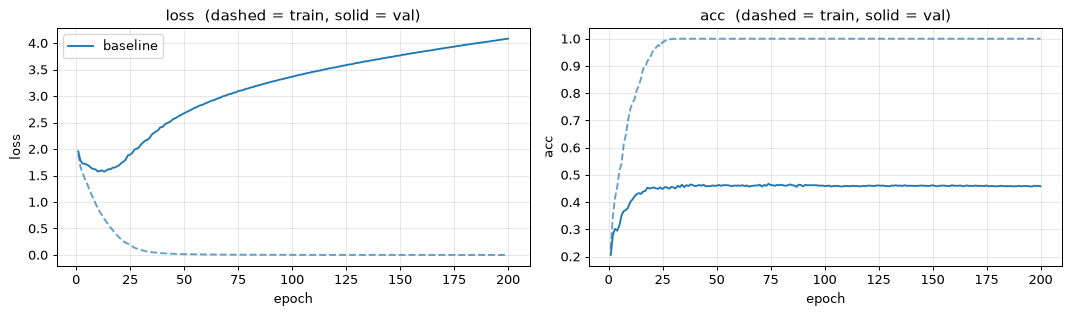

[baseline] val acc 0.458 | val loss 4.083


In [6]:
seed_everything(SEED)
baseline = make_mlp(**MLP)
print(f"parameters: {sum(p.numel() for p in baseline.parameters()):,}")
hist_baseline = train_model(baseline, DATA["X_train"], DATA["y_train"], **CLF,
                            X_val=DATA["X_val"], y_val=DATA["y_val"])
plot_histories({"baseline": hist_baseline})
record_result("baseline", baseline)

The **generalization gap** (train accuracy 100% vs. validation accuracy around 45–50%) is what every later
section tries to reduce.

---
## 1. Overfitting and the bias–variance trade-off

Here I measure bias and variance directly and see how the best capacity depends on the amount of data.

The lecture decomposed the expected test error of a model trained on a *random* training set into

$$\mathbb{E}_{\mathcal{D}}\big[(f(x;\mathcal{D}) - y)^2\big]
  = \underbrace{\big(\bar f(x) - f^*(x)\big)^2}_{\text{bias}^2}
  + \underbrace{\mathbb{E}_{\mathcal{D}}\big[(f(x;\mathcal{D}) - \bar f(x))^2\big]}_{\text{variance}}
  + \underbrace{\sigma^2}_{\text{noise}},
\qquad \bar f(x) = \mathbb{E}_{\mathcal{D}}[f(x;\mathcal{D})].$$

To measure bias and variance we must train **hundreds** of models on independently sampled datasets. To make this
cheap we use the model from the *Bias–variance trade-off* slide: a shallow ReLU network whose hidden units have
**fixed** kinks at $0, \tfrac1n, \dots, \tfrac{n-1}{n}$, so that it is piecewise linear with $n$ regions:

$$f(x) = \beta_0 + \sum_{k=0}^{n-1} \beta_{k+1}\,\mathrm{ReLU}\!\left(x - \tfrac{k}{n}\right).$$

Only the output layer $\beta$ is learned, so training is a linear least-squares problem with a closed-form solution.
The number of regions $n$ is the **capacity** of the model.

### 1.1 The model

* `relu_features(x, n_regions)` returns the design matrix of shape `(N, n_regions + 1)`: a column of ones followed by $\mathrm{ReLU}(x - k/n)$ for $k = 0, \dots, n-1$.
* `fit_shallow_relu(x, y, n_regions)` returns the least-squares output weights $\beta$ as `torch.linalg.pinv(Phi) @ y`, which gives the minimum-norm solution when some region contains no data point.
* `predict_shallow_relu(beta, x, n_regions)` gives the model output.

In [7]:
def relu_features(x, n_regions):
    columns = [torch.ones_like(x)]
    for k in range(n_regions):
        columns.append(torch.relu(x - k / n_regions))
    return torch.cat(columns, dim=1)


def fit_shallow_relu(x, y, n_regions):
    Phi = relu_features(x, n_regions)
    return torch.linalg.pinv(Phi) @ y


def predict_shallow_relu(beta, x, n_regions):
    return relu_features(x, n_regions) @ beta

In [8]:
# Tests for 1.1
_x = torch.linspace(0, 1, 200)[:, None]
_phi = relu_features(_x, 4)
assert _phi.shape == (200, 5) and torch.all(_phi[:, 0] == 1)
assert torch.allclose(_phi[:, 3], torch.relu(_x[:, 0] - 0.5)), "column k+1 must be ReLU(x - k/n)"
_beta = fit_shallow_relu(_x, _x ** 2, 1)                       # 1 region = a straight line
_line = np.polyfit(_x[:, 0].numpy(), (_x ** 2)[:, 0].numpy(), 1)
assert np.allclose(predict_shallow_relu(_beta, _x, 1)[:, 0].numpy(), np.polyval(_line, _x[:, 0].numpy()), atol=1e-4)
_y = torch.tensor(true_fn(_x.numpy()), dtype=torch.float32)
assert F.mse_loss(predict_shallow_relu(fit_shallow_relu(_x, _y, 50), _x, 50), _y) < 1e-3, "50 regions should fit a sine almost exactly"
print("1.1 tests passed")

1.1 tests passed


**Variance of the trained models**. A reproduction of the *Variance of trained models on different sample
sets* slide: a model with 3 regions trained on three different random datasets of size 6, 10 and 100
(top rows), and the mean ± 2 std of the prediction over 200 datasets (bottom row).

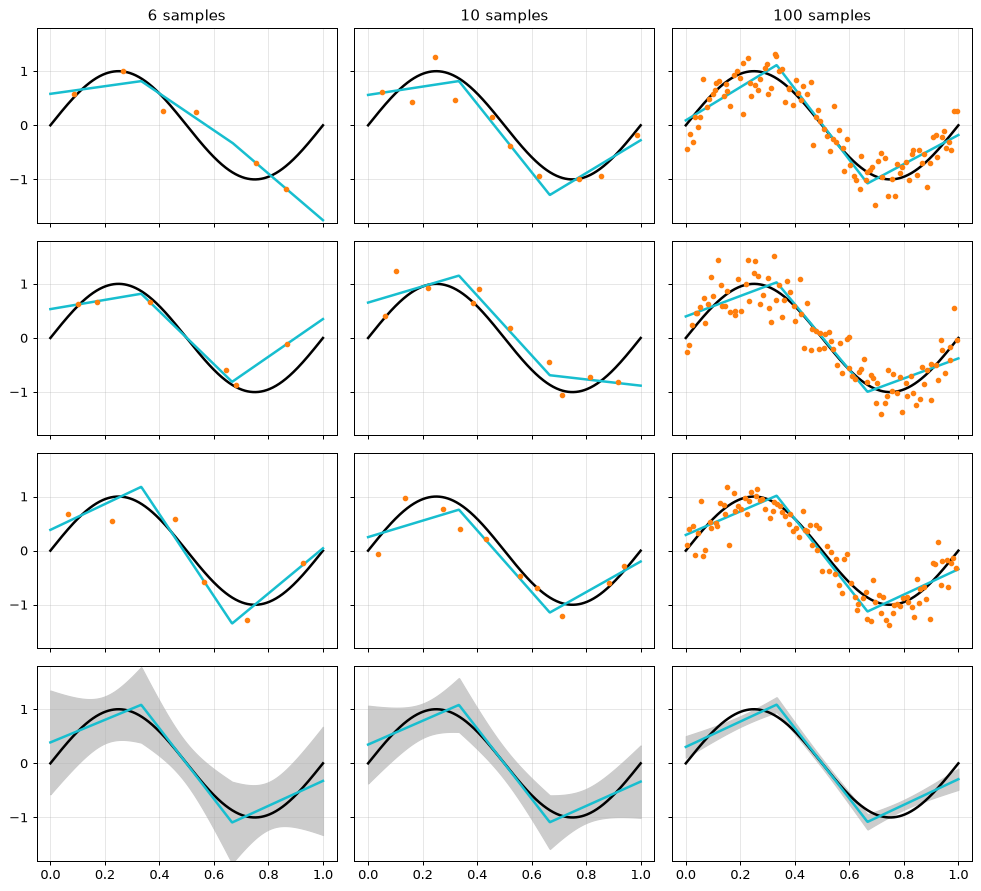

In [9]:
fig, axs = plt.subplots(4, 3, figsize=(11, 10), sharex=True, sharey=True)
for j, n in enumerate([6, 10, 100]):
    preds = []
    for r in range(200):
        Xr, Yr = make_toy_data(n, noise_std=0.3, seed=1000 + r)
        pr = predict_shallow_relu(fit_shallow_relu(Xr, Yr, 3), X_GRID, 3)[:, 0]
        preds.append(pr)
        if r < 3:
            axs[r, j].plot(X_GRID, Y_GRID_TRUE, "k", lw=2); axs[r, j].plot(X_GRID, pr, "C9", lw=2)
            axs[r, j].scatter(Xr, Yr, c="C1", s=12, zorder=3)
    preds = torch.stack(preds)
    m, s = preds.mean(0), preds.std(0)
    axs[3, j].fill_between(X_GRID[:, 0], m - 2 * s, m + 2 * s, color="0.8")
    axs[3, j].plot(X_GRID, Y_GRID_TRUE, "k", lw=2); axs[3, j].plot(X_GRID, m, "C9", lw=2)
    axs[0, j].set_title(f"{n} samples")
axs[0, 0].set_ylim(-1.8, 1.8)
plt.tight_layout(); plt.show()

### 1.2 Measuring bias and variance

`bias_variance(n_regions, n_samples, n_datasets=200, noise_std=0.3)` draws dataset `r` with `make_toy_data(n_samples, noise_std, seed=1000 + r)`, fits the model and predicts on `X_GRID`. Averaged over the grid, it estimates
$$\text{bias}^2 = \operatorname{mean}_x\big(\bar f(x) - f^*(x)\big)^2, \qquad
  \text{variance} = \operatorname{mean}_x \operatorname{mean}_r \big(f_r(x) - \bar f(x)\big)^2 ,$$
where $f^*$ is `Y_GRID_TRUE`.

In [10]:
def bias_variance(n_regions, n_samples, n_datasets=200, noise_std=0.3):
    preds = []
    for r in range(n_datasets):
        X, Y = make_toy_data(n_samples, noise_std, seed=1000 + r)
        beta = fit_shallow_relu(X, Y, n_regions)
        preds.append(predict_shallow_relu(beta, X_GRID, n_regions)[:, 0])
    preds = torch.stack(preds)              # (n_datasets, grid points)
    f_bar = preds.mean(dim=0)               # average model over the datasets
    bias2 = ((f_bar - Y_GRID_TRUE[:, 0]) ** 2).mean()
    variance = ((preds - f_bar) ** 2).mean()
    return bias2.item(), variance.item()

In [11]:
# Tests for 1.2 — the datasets are seeded, so the result is deterministic and can be compared with fixed values
_b, _v = bias_variance(3, 15)
assert np.isclose(_b, 0.01614, rtol=1e-2), f"bias² for 3 regions, N = 15 should be ≈ 0.01614, got {_b:.5f}"
assert np.isclose(_v, 0.02628, rtol=1e-2), f"variance for 3 regions, N = 15 should be ≈ 0.02628, got {_v:.5f}"
_b, _v = bias_variance(1, 15, n_datasets=50)
assert np.isclose(_b, 0.197, rtol=0.05) and _v < 0.03, "a straight line: bias² ≈ 0.2 (the sine cannot be fitted), small variance"
print("1.2 tests passed")

1.2 tests passed


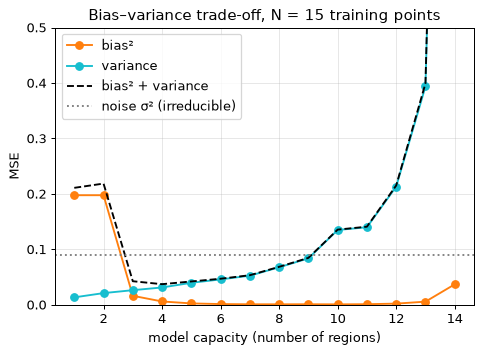

capacity with the lowest bias² + variance: 4


In [12]:
# The bias-variance curve (≈ 10 s)
N_BV, NOISE_BV = 15, 0.3
caps = list(range(1, 15))
bv = np.array([bias_variance(c, N_BV) for c in caps])
plt.figure(figsize=(6, 4))
plt.plot(caps, bv[:, 0], "o-", c="C1", label="bias²")
plt.plot(caps, bv[:, 1], "o-", c="C9", label="variance")
plt.plot(caps, bv.sum(1), "k--", label="bias² + variance")
plt.axhline(NOISE_BV ** 2, c="0.5", ls=":", label="noise σ² (irreducible)")
plt.ylim(0, 0.5); plt.xlabel("model capacity (number of regions)"); plt.ylabel("MSE")
plt.title(f"Bias–variance trade-off, N = {N_BV} training points"); plt.legend(); plt.show()
best_capacity = caps[int(np.argmin(bv.sum(1)))]
print("capacity with the lowest bias² + variance:", best_capacity)

> (a) Which term dominates at low capacity and which at high capacity? Where is the sweet spot?
> (b) Why does the variance explode as the number of regions approaches the number of training points ($N = 15$)?
> (c) How does the picture change with $N = 100$ training points, and what does that say about the best capacity and the amount of data?

**(a)** At low capacity bias dominates: with 1 or 2 regions bias² is 0.198 and the variance only 0.013 to 0.021, because a straight line cannot follow a sine. (Two regions are no better than one: the only kink sits at $x = 0.5$, and since the sine is point-symmetric around $(0.5, 0)$ the best two-piece fit is the same straight line.) As capacity grows, bias² drops fast (0.016 at 3 regions, 0.006 at 4, below 0.001 from 8 on) while the variance grows: 0.031 at 4, 0.135 at 10, 0.394 at 13 and 2.37 at 14. The sweet spot is 4 regions, where bias² + variance is lowest (0.037).

**(b)** The model has $n + 1$ free parameters. When $n + 1$ gets close to $N = 15$ the least-squares system is almost square, so the fit goes through (almost) every training point, noise included. The points are stratified, so each region holds about one point, and the slope in a region is set by two neighbouring noisy points that can be very close in $x$. A small difference in $y$ divided by a small distance in $x$ gives a huge slope, and the matrix becomes ill-conditioned, so the pseudo-inverse amplifies the noise. Every new dataset then gives a wildly different curve, which is exactly what variance measures. (Past this point the variance comes down again, 0.22 at 20 regions and 0.16 at 50, because `pinv` picks the minimum-norm solution among many exact fits. This is a first glimpse of the double descent of Section 7.)

**(c)** With $N = 100$ the bias does not change, since it depends only on what the model *can* represent (bias² is still 0.016 at 3 regions and 0.006 at 4). The variance falls roughly like $1/N$: at 4 regions it goes from 0.031 to 0.0044, and at 14 regions from 2.37 to 0.014. So the variance curve becomes much flatter and the minimum moves to the right: the lowest bias² + variance is at 5 to 6 regions (0.0078), and the curve stays almost flat up to about 10 regions. The best capacity grows with the amount of data: more data pays for more parameters, because each parameter is estimated from more points.

---
## 2. L2 regularization and weight decay

What λ does to the learned function (toy problem), to the weights and to the loss (MNIST-1D), and how the "weight decay" and "Gaussian prior" views connect.

Explicit regularization adds a term to the loss that encodes a preference (an *inductive bias*):

$$J(W) = \frac{1}{N}\sum_{n=1}^{N} \mathrm{loss}\big(y^{(n)}, f(x^{(n)}; W)\big) + \lambda R(W),
\qquad R(W) = \sum_{k}\sum_{l} W_{k,l}^2 .$$

Below I (2.1) implement $R(W)$, (2.2) look at what $\lambda$ does to the learned function,
(2.3) check numerically that "L2 in the loss" and "weight decay" are the same thing for SGD,
(2.4) tune $\lambda$ on MNIST-1D, and (2.5) connect $\lambda$ to a Gaussian prior (MAP estimation).

### 2.1 The L2 penalty

`l2_penalty(model)` is the sum of squares of all weights of the model. As in the lecture, biases are not regularized. The weights of an `nn.Linear` are the parameters whose names end with `"weight"`, and the result is a differentiable scalar tensor.

In [13]:
def l2_penalty(model):
    total = torch.zeros(())
    for name, p in model.named_parameters():
        if name.endswith("weight"):
            total = total + (p ** 2).sum()
    return total

In [14]:
# Tests for 2.1
_m = nn.Sequential(nn.Linear(2, 2), nn.ReLU(), nn.Linear(2, 1))
with torch.no_grad():
    _m[0].weight.copy_(torch.tensor([[1., 2.], [3., 4.]])); _m[0].bias.fill_(100.)
    _m[2].weight.copy_(torch.tensor([[-1., 0.5]]));        _m[2].bias.fill_(-100.)
_r = l2_penalty(_m)
assert torch.is_tensor(_r) and _r.ndim == 0, "must return a scalar tensor"
assert abs(_r.item() - 31.25) < 1e-5, f"expected 1+4+9+16+1+0.25 = 31.25 (biases excluded), got {_r.item()}"
_r.backward()
assert torch.allclose(_m[0].weight.grad, 2 * _m[0].weight), "gradient of R(W) w.r.t. W must be 2W"
assert _m[0].bias.grad is None or torch.all(_m[0].bias.grad == 0), "biases must not be penalized"
print("2.1 tests passed")

2.1 tests passed


> Why are biases usually excluded from weight decay?

1. A bias does not make the function more complex. A weight sets how strongly a unit reacts to its input (the slope of the function), so large weights mean steep, wiggly functions, and shrinking them makes $f$ smoother. A bias only shifts a unit's kink or the output up and down. Shrinking it towards 0 gives no smoothness, it just pulls the output towards 0 and can cause underfitting (for example, the right constant offset of the data would be penalized).
2. There are very few biases, one per unit against fan-in weights per unit. In our MLP there are $256 + 256 + 10 = 522$ biases against 78,336 weights, so the biases add almost no capacity to overfit with, and leaving them free costs nothing in variance.

### 2.2 What does λ do to the function?

The lecture's *Regularization parameter* slide, on the toy dataset. For each λ in `LAMBDAS_TOY`, a fresh `make_mlp(**TOY_MLP)` starts from the same initialization (`seed_everything(SEED)`) and trains with `penalty_fn=l2_penalty`. The table records the data MSE on the training set, the true test MSE (`toy_test_mse`) and $\|W\|^2$. *(≈ 1 min in total)*

,train_mse,test_mse,weight_l2
lam,,,
0.0000,0.0001,0.0460,425.7412
0.0001,0.0119,0.0344,34.3235
0.0010,0.0162,0.0220,19.7654
0.0100,0.0760,0.0509,10.4425
0.0300,0.1438,0.1077,6.4065
0.1000,0.4947,0.4990,0.0000


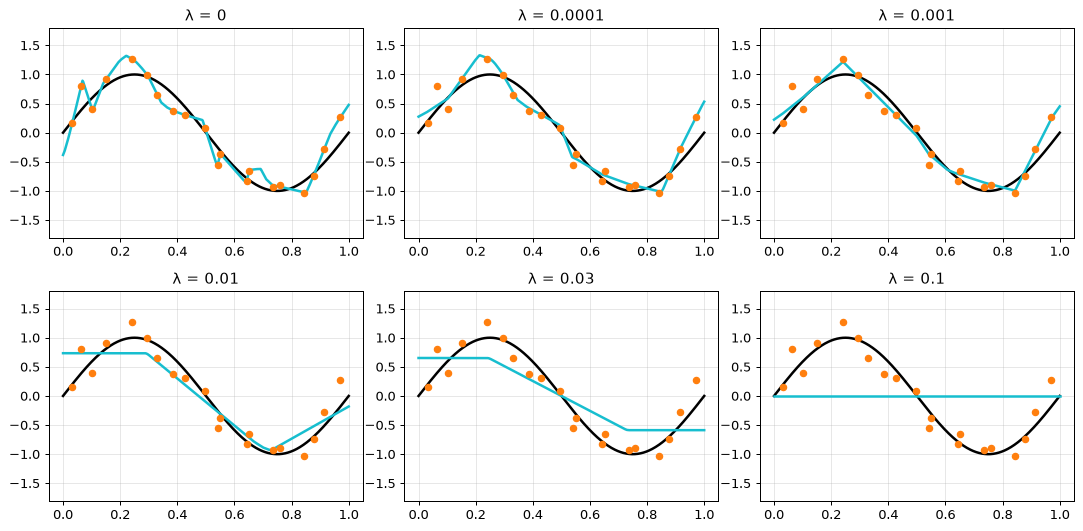

In [15]:
LAMBDAS_TOY = [0, 1e-4, 1e-3, 1e-2, 3e-2, 1e-1]
TOY_MLP = dict(in_dim=1, out_dim=1, hidden=100, depth=3)
TOY_TRAIN = dict(epochs=8000, lr=3e-3, batch_size=None, eval_every=8000)  # full-batch Adam

toy_models, toy_rows = {}, []
for lam in LAMBDAS_TOY:
    seed_everything(SEED)
    model = make_mlp(**TOY_MLP)
    hist = train_model(model, X_TOY, Y_TOY, **TOY_TRAIN, penalty_fn=l2_penalty, lam=lam)
    toy_models[lam] = model
    toy_rows.append(dict(lam=lam, train_mse=hist["train_loss"][-1],
                         test_mse=toy_test_mse(model), weight_l2=l2_penalty(model).item()))

toy_l2_table = pd.DataFrame(toy_rows).set_index("lam")
display(toy_l2_table.round(4))
plot_toy_fits({f"λ = {lam:g}": m for lam, m in toy_models.items()})

In [16]:
# Tests for 2.2 (implementation)
assert list(toy_models) == LAMBDAS_TOY and len(toy_rows) == len(LAMBDAS_TOY)
assert set(toy_l2_table.columns) == {"train_mse", "test_mse", "weight_l2"}
assert len({id(m) for m in toy_models.values()}) == len(LAMBDAS_TOY), "train a fresh model for every λ"
for _lam, _m in toy_models.items():
    assert np.isclose(toy_l2_table.loc[_lam, "weight_l2"], l2_penalty(_m).item()), "weight_l2 must be l2_penalty(model)"
    assert np.isclose(toy_l2_table.loc[_lam, "test_mse"], toy_test_mse(_m)), "test_mse must be toy_test_mse(model)"
print("2.2 tests passed")
# Sanity checks (results)
expect(toy_l2_table["weight_l2"].is_monotonic_decreasing, "a larger λ gives smaller weights")
expect(toy_l2_table.loc[0, "train_mse"] < toy_l2_table.loc[1e-1, "train_mse"], "λ = 0 fits the training data best")
expect(toy_l2_table["test_mse"].idxmin() not in (0, 1e-1), "the best true test MSE is at an intermediate λ")

2.2 tests passed
✓ a larger λ gives smaller weights
✓ λ = 0 fits the training data best
✓ the best true test MSE is at an intermediate λ


> (a) How do the training MSE and the true test MSE change as $\lambda$ grows? Which $\lambda$ over-fits and which under-fits?
> (b) At $\lambda = 0.1$ the model outputs an almost constant function. Which constant, and why?

**(a)** The training MSE grows steadily with $\lambda$: 0.0001, 0.012, 0.016, 0.076, 0.144, 0.495. The true test MSE first falls and then rises: 0.046 at $\lambda = 0$, 0.034 at $10^{-4}$, **0.022 at $10^{-3}$** (the best), then 0.051, 0.108 and 0.499. $\lambda = 0$ over-fits: the curve passes through every noisy point with sharp wiggles, and its weights are huge ($\|W\|^2 = 426$). $\lambda = 10^{-3}$ follows the sine and ignores most of the noise. From $\lambda = 10^{-2}$ on the model under-fits: the peaks are cut flat (the network cannot afford the steep slopes needed to reach $\pm 1$), and at $\lambda = 0.1$ it is a constant.

**(b)** The constant is about $-0.003$, the mean of the 20 training targets. At $\lambda = 0.1$ the penalty pushes every weight to zero ($\|W\|^2 = 0.0000$ in the table). The last layer's weights are then zero, so the output is just the output bias, and the biases are not regularized. The best constant under MSE is the mean of the targets, so the bias goes there. The numbers confirm it: the training MSE 0.4947 is exactly the variance of the training targets, and the test MSE 0.499 is the mean of $\sin^2(2\pi x)$, about 0.5.

### 2.3 L2 penalty = weight decay (for SGD)

For plain gradient descent the lecture showed

$$W \leftarrow W - \alpha \nabla_W \big(L(W) + \lambda \|W\|^2\big)
  \;=\; W\,(1 - 2\alpha\lambda) - \alpha \nabla_W L(W).$$

Both sides of this equation, as one manual SGD step on the MSE loss inside `torch.no_grad()`, without `torch.optim`:

* **(a)** `sgd_step_l2_in_loss`: backprop through `data_loss + lam * l2_penalty(model)` and take a plain gradient step.
* **(b)** `sgd_step_weight_decay`: backprop through the **data loss only**, then apply the right-hand side of the
  equation: weights are multiplied by $(1 - 2\alpha\lambda)$ before the gradient step; biases get a plain gradient step.

The test also compares both with PyTorch's `torch.optim.SGD(weight_decay=wd)`. Two details of its configuration:
`weight_decay` adds `wd * p` to the gradient of **every** parameter it is given, so the biases go in a separate
*parameter group*, and `wd = 2λ` because our penalty is $\lambda\|W\|^2$ (not $\tfrac{\lambda}{2}\|W\|^2$).

In [17]:
def sgd_step_l2_in_loss(model, X, y, lr, lam):
    model.zero_grad(set_to_none=True)
    loss = F.mse_loss(model(X), y) + lam * l2_penalty(model)
    loss.backward()
    with torch.no_grad():
        for p in model.parameters():
            p -= lr * p.grad


def sgd_step_weight_decay(model, X, y, lr, lam):
    model.zero_grad(set_to_none=True)
    F.mse_loss(model(X), y).backward()
    with torch.no_grad():
        for name, p in model.named_parameters():
            if name.endswith("weight"):
                p *= 1 - 2 * lr * lam      # the decay, before the gradient step
            p -= lr * p.grad

In [18]:
# Tests for 2.3
seed_everything(SEED)
_ma = make_mlp(1, 1, hidden=32, depth=2)
_mb, _mc = copy.deepcopy(_ma), copy.deepcopy(_ma)
_opt = torch.optim.SGD([{"params": [p for n, p in _mc.named_parameters() if n.endswith("weight")], "weight_decay": 2 * 0.01},
                        {"params": [p for n, p in _mc.named_parameters() if not n.endswith("weight")], "weight_decay": 0.0}],
                       lr=0.05)
_w0 = _ma[0].weight.detach().clone()
for _ in range(50):
    sgd_step_l2_in_loss(_ma, X_TOY, Y_TOY, lr=0.05, lam=0.01)
    sgd_step_weight_decay(_mb, X_TOY, Y_TOY, lr=0.05, lam=0.01)
    _opt.zero_grad(); F.mse_loss(_mc(X_TOY), Y_TOY).backward(); _opt.step()
for (n, pa), pb, pc in zip(_ma.named_parameters(), _mb.parameters(), _mc.parameters()):
    assert torch.allclose(pa, pb, atol=1e-5), f"(a) and (b) differ in {n}"
    assert torch.allclose(pa, pc, atol=1e-5), f"(a) and torch.optim.SGD(weight_decay) differ in {n}"
assert not torch.allclose(_w0, _ma[0].weight), "parameters did not change"
print("2.3 tests passed: L2-in-the-loss and weight decay give identical SGD trajectories")

2.3 tests passed: L2-in-the-loss and weight decay give identical SGD trajectories


### 2.4 Tuning λ on MNIST-1D

Now the real problem. For every λ in `LAMBDAS_CLF`, a fresh `make_mlp(**MLP)` trains from the same seed with the L2 penalty. `best_lam` is chosen by the validation accuracy at the end of training, and that model goes on the leaderboard. *(≈ 30–40 s)*

In [19]:
LAMBDAS_CLF = [0, 3e-4, 1e-3, 3e-3, 1e-2]
l2_hists, l2_models = {}, {}
for lam in LAMBDAS_CLF:
    seed_everything(SEED)
    model = make_mlp(**MLP)
    l2_hists[lam] = train_model(model, DATA["X_train"], DATA["y_train"], **CLF,
                                penalty_fn=l2_penalty, lam=lam,
                                X_val=DATA["X_val"], y_val=DATA["y_val"])
    l2_models[lam] = model

best_lam = max(LAMBDAS_CLF, key=lambda lam: l2_hists[lam]["val_acc"][-1])
record_result(f"L2 (λ={best_lam:g})", l2_models[best_lam])

[L2 (λ=0.001)] val acc 0.514 | val loss 2.029


,train acc,val acc,val loss,‖W‖²
0.0000,1.000,0.458,4.083,789.553
0.0003,1.000,0.488,2.371,322.864
0.0010,1.000,0.514,2.029,229.802
0.0030,1.000,0.508,1.652,164.945
0.0100,0.655,0.456,1.400,51.205


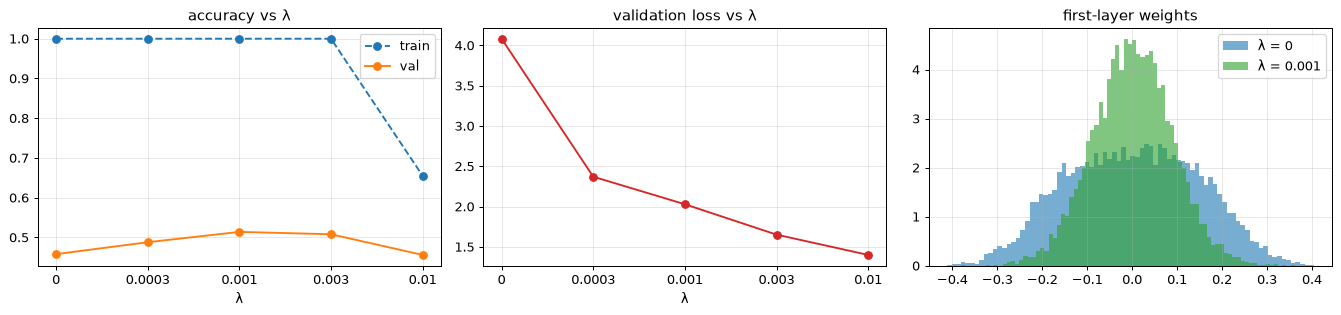

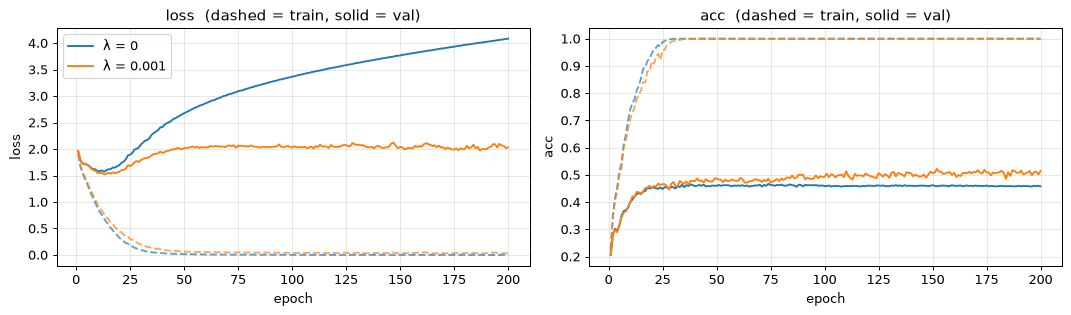

In [20]:
# Summary plots for 2.4
summary = pd.DataFrame({lam: {"train acc": h["train_acc"][-1], "val acc": h["val_acc"][-1],
                              "val loss": h["val_loss"][-1], "‖W‖²": l2_penalty(l2_models[lam]).item()}
                        for lam, h in l2_hists.items()}).T
display(summary.round(3))

fig, axs = plt.subplots(1, 3, figsize=(15, 3.6))
xs = [str(l) for l in LAMBDAS_CLF]
axs[0].plot(xs, summary["train acc"], "o--", label="train"); axs[0].plot(xs, summary["val acc"], "o-", label="val")
axs[0].set_title("accuracy vs λ"); axs[0].legend()
axs[1].plot(xs, summary["val loss"], "o-", c="C3"); axs[1].set_title("validation loss vs λ")
for lam, c in [(0, "C0"), (best_lam, "C2")]:
    axs[2].hist(l2_models[lam][0].weight.detach().flatten(), bins=80, alpha=0.6, color=c, label=f"λ = {lam:g}", density=True)
axs[2].set_title("first-layer weights"); axs[2].legend()
for ax in axs[:2]:
    ax.set_xlabel("λ")
plt.tight_layout(); plt.show()
plot_histories({f"λ = {lam:g}": l2_hists[lam] for lam in [0, best_lam]})

In [21]:
# Tests for 2.4 (implementation)
assert set(l2_hists) == set(LAMBDAS_CLF) and set(l2_models) == set(LAMBDAS_CLF)
assert best_lam == max(LAMBDAS_CLF, key=lambda lam: l2_hists[lam]["val_acc"][-1]), "choose λ by validation accuracy"
assert f"L2 (λ={best_lam:g})" in RESULTS, "record the chosen model on the leaderboard"
print("2.4 tests passed")
# Sanity checks (results)
expect(l2_hists[best_lam]["val_loss"][-1] < l2_hists[0]["val_loss"][-1], "L2 reduces the validation loss")
expect(l2_penalty(l2_models[best_lam]) < l2_penalty(l2_models[0]), "L2 shrinks the weights")

2.4 tests passed
✓ L2 reduces the validation loss
✓ L2 shrinks the weights


> (a) From the unregularized model to the best one, how did the train accuracy, the validation accuracy and the validation loss change? Why can the cross-entropy explode while the accuracy barely changes?
> (b) Why choose $\lambda$ on the validation set and not on the test set?

**(a)** From $\lambda = 0$ to $\lambda = 10^{-3}$: the train accuracy stays at 1.000, the validation accuracy goes from 0.458 to 0.514 (+5.6 points), and the validation loss from 4.08 to 2.03, half of what it was. The loss improved the most. Cross-entropy only cares about the probability given to the correct class, and $-\log p$ has no upper bound. The over-fitted network has large weights (the blue histogram spreads to $\pm 0.4$, while the $\lambda = 10^{-3}$ weights stay mostly within $\pm 0.2$; $\|W\|^2$ drops from 790 to 230). Large weights give large logits, so the network is extremely confident on every validation example, including the half it gets wrong. A confident mistake with $p = 10^{-4}$ on the true class costs $-\log 10^{-4} \approx 9.2$, so a few such mistakes make the mean loss explode. Accuracy only checks the argmax, so it barely notices. L2 keeps the weights, and therefore the logits, small, which mostly fixes the overconfidence and much less the argmax.

**(b)** Choosing $\lambda$ is part of training: whatever data we use to make that choice, the final model has been fitted to it. If we pick $\lambda$ on the test set, we pick the setting that happens to do best on those particular 1000 examples, part of which is luck (with 1000 examples, one accuracy number has a standard error of about 1.6 points, similar to the gaps between our $\lambda$s). The test score is then optimistically biased, and we have no data left that gives an honest estimate of how the model does on new data. The validation set absorbs that bias, and the test set stays untouched for the final report.

### 2.5 The probabilistic view: λ is a prior

The lecture showed that L2 regularization is MAP estimation with a Gaussian prior on the weights,
$p(W) = \mathcal{N}(0, \alpha^2 I)$. Our objective is the **mean** cross-entropy (the mean negative log-likelihood)
over $N$ training examples plus $\lambda\|W\|^2$.

Starting from $\arg\max_W \big[\log p(W) + \sum_n \log p(y^{(n)} \mid x^{(n)}, W)\big]$, I derive the relation between $\lambda$, $N$ and the prior standard deviation $\alpha$, and `prior_std_from_lambda(lam, n)` returns $\alpha$.

With the prior $p(W) = \mathcal N(0, \alpha^2 I)$ we have $\log p(W) = -\frac{\|W\|^2}{2\alpha^2} + \text{const}$. So

$$\arg\max_W \Big[\log p(W) + \sum_n \log p(y^{(n)} \mid x^{(n)}, W)\Big]
= \arg\min_W \Big[\sum_n -\log p(y^{(n)} \mid x^{(n)}, W) + \frac{\|W\|^2}{2\alpha^2}\Big].$$

Dividing the objective by $N > 0$ does not change the minimizer:

$$= \arg\min_W \Big[\frac1N \sum_n -\log p(y^{(n)} \mid x^{(n)}, W) + \frac{1}{2N\alpha^2}\|W\|^2\Big].$$

The first term is our mean cross-entropy, so comparing with $J(W) = \text{mean NLL} + \lambda\|W\|^2$:

$$\lambda = \frac{1}{2N\alpha^2} \qquad\Longleftrightarrow\qquad \alpha = \frac{1}{\sqrt{2N\lambda}}.$$

In [22]:
def prior_std_from_lambda(lam, n):
    # lam = 1 / (2 n alpha^2)  =>  alpha = 1 / sqrt(2 n lam)
    return 1 / math.sqrt(2 * n * lam)

In [23]:
# Tests for 2.5
assert abs(prior_std_from_lambda(1e-3, 1000) - 1 / math.sqrt(2)) < 1e-9
assert abs(prior_std_from_lambda(0.5, 1) - 1.0) < 1e-9
print(f"2.5 tests passed. The best λ = {best_lam:g} corresponds to a prior std α = "
      f"{prior_std_from_lambda(best_lam, len(DATA['X_train'])):.3f}")

2.5 tests passed. The best λ = 0.001 corresponds to a prior std α = 0.707


> With 10× more training data and the same prior $\alpha$, how should $\lambda$ change?

$\lambda = 1/(2N\alpha^2)$, so with the same $\alpha$ and $10N$ examples, $\lambda$ should be **10 times smaller**. The prior is counted once, while the likelihood has one term per example. Because we use the *mean* loss, the prior's share of the objective is $1/N$ of what the data says. With more data there is more evidence about $W$, so the data should outweigh the prior and we need less regularization. In the limit of infinite data the MAP estimate becomes the maximum-likelihood estimate. (For our best $\lambda = 10^{-3}$ and $N = 1000$, $\alpha = 0.707$; with 10,000 examples the same prior means $\lambda = 10^{-4}$.)

---
## 3. Early stopping

Training time is itself a regularizer, and it resembles L2. Which metric I monitor changes the model I get.

*"Stopping the training procedure before it has fully converged."* We track performance on a held-out validation set
and stop when it has not improved for `patience` evaluations, then **restore the best weights seen so far**.

### 3.1 An `EarlyStopping` callback

The callback plugs into `train_model` (Section 0.3):
* `monitor` is a key of the history (`"val_loss"` or `"val_acc"`), and `mode` is `"min"` or `"max"`.
* `on_epoch_end(model, history)` reads the last value of `history[monitor]`. If it is strictly better than the best value so far, it stores the value, the epoch and a deep copy of `model.state_dict()` and resets the counter; otherwise it increments the counter. It returns `True` (stop) when the counter reaches `patience`.
* `on_train_end(model, history)` loads the best state back into the model if `restore_best` is set.

In [24]:
class EarlyStopping:
    def __init__(self, patience=20, monitor="val_loss", mode="min", restore_best=True):
        self.patience, self.monitor, self.mode, self.restore_best = patience, monitor, mode, restore_best
        self.best_value, self.best_epoch, self.best_state = None, None, None
        self.counter = 0

    def on_epoch_end(self, model, history):
        value = history[self.monitor][-1]
        if self.best_value is None:
            improved = True
        elif self.mode == "min":
            improved = value < self.best_value
        else:
            improved = value > self.best_value

        if improved:
            self.best_value = value
            self.best_epoch = history["epoch"][-1]
            self.best_state = copy.deepcopy(model.state_dict())
            self.counter = 0
        else:
            self.counter += 1
        return self.counter >= self.patience

    def on_train_end(self, model, history):
        if self.restore_best and self.best_state is not None:
            model.load_state_dict(self.best_state)

In [25]:
# Tests for 3.1 — a fake training run where the "model" parameter is set to the epoch number
def _fake_run(values, cb, key):
    model, hist = nn.Linear(1, 1), {"epoch": [], key: []}
    for epoch, v in enumerate(values, start=1):
        with torch.no_grad():
            model.weight.fill_(epoch)
        hist["epoch"].append(epoch); hist[key].append(v)
        if cb.on_epoch_end(model, hist):
            break
    cb.on_train_end(model, hist)
    return epoch, model.weight.item()

_cb = EarlyStopping(patience=3, monitor="val_loss", mode="min")
_stop, _w = _fake_run([5, 4, 3, 3.5, 3.2, 3.1, 3.3, 1.0], _cb, "val_loss")
assert _stop == 6, f"should stop after 3 epochs without improvement (epoch 6), stopped at {_stop}"
assert _cb.best_epoch == 3 and _cb.best_value == 3, "best epoch/value are wrong"
assert _w == 3, "the weights of the best epoch must be restored (the state_dict must be deep-copied)"
_cb = EarlyStopping(patience=2, monitor="val_acc", mode="max")
_stop, _w = _fake_run([0.1, 0.5, 0.5, 0.4, 0.9], _cb, "val_acc")
assert (_stop, _cb.best_epoch, _w) == (4, 2, 2), "mode='max' or the strict-improvement rule is wrong"
_cb = EarlyStopping(patience=2, restore_best=False)
assert _fake_run([3, 2, 4, 5], _cb, "val_loss")[1] == 4, "restore_best=False must keep the last weights"
print("3.1 tests passed")

3.1 tests passed


### 3.2 Early stopping as regularization

On the toy problem we can "validate" against the **true** function: we pass the dense grid
`X_GRID, Y_GRID_TRUE` as the validation set, so `val_loss` is the true test MSE. (This is only possible in a toy
problem — in practice the validation set is held-out data.) We train the unregularized network for 20 000 steps and
look at the fit during training, reproducing the *Early stopping: Example* slide. *(≈ 25 s)*

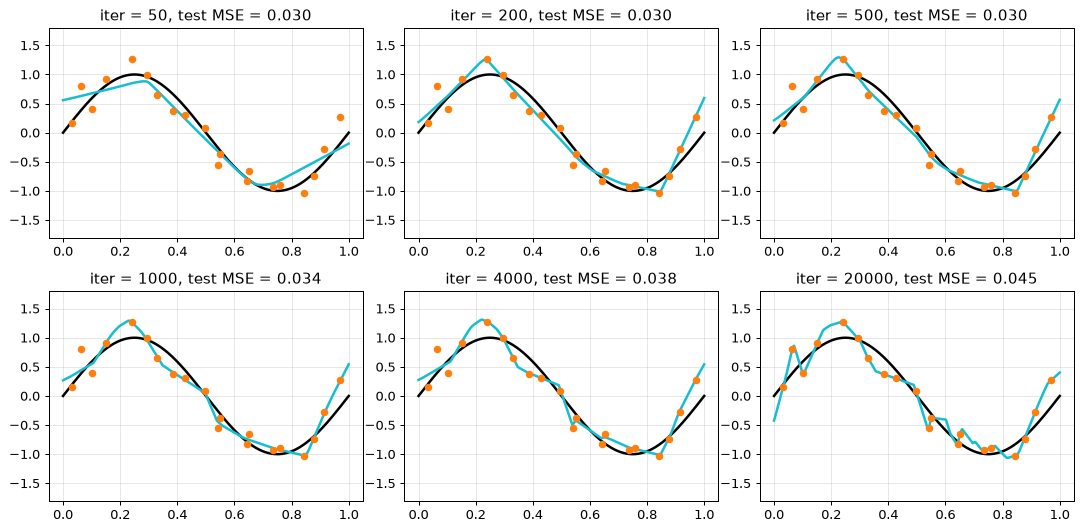

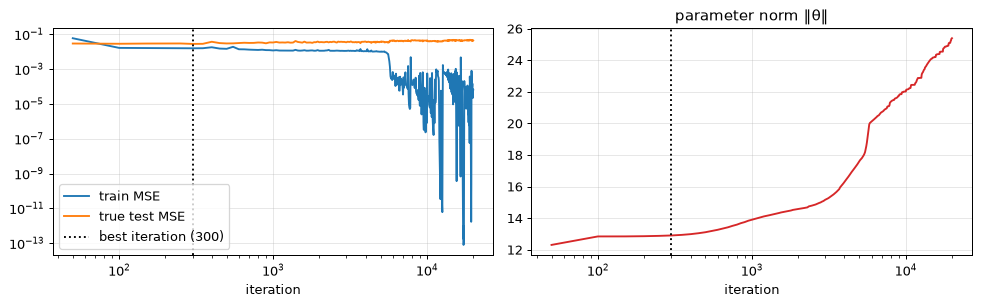

In [26]:
class Snapshots:
    """Keep a copy of the model at the given epochs."""
    def __init__(self, epochs):
        self.epochs, self.models = set(epochs), {}

    def on_epoch_end(self, model, history):
        if history["epoch"][-1] in self.epochs:
            self.models[history["epoch"][-1]] = copy.deepcopy(model)
        return False


seed_everything(SEED)
toy_es_model = make_mlp(**TOY_MLP)
snaps = Snapshots([50, 200, 500, 1000, 4000, 20000])
toy_es = EarlyStopping(patience=10**9, monitor="val_loss", mode="min")  # never stops: only tracks the best step
hist_toy_es = train_model(toy_es_model, X_TOY, Y_TOY, epochs=20000, lr=3e-3, eval_every=50,
                          X_val=X_GRID, y_val=Y_GRID_TRUE, callbacks=[snaps, toy_es])

plot_toy_fits({f"iter = {e}, test MSE = {toy_test_mse(m):.3f}": m for e, m in snaps.models.items()})
fig, axs = plt.subplots(1, 2, figsize=(11, 3.5))
axs[0].plot(hist_toy_es["epoch"], hist_toy_es["train_loss"], label="train MSE")
axs[0].plot(hist_toy_es["epoch"], hist_toy_es["val_loss"], label="true test MSE")
axs[0].axvline(toy_es.best_epoch, c="k", ls=":", label=f"best iteration ({toy_es.best_epoch})")
axs[0].set_yscale("log"); axs[0].legend()
axs[1].plot(hist_toy_es["epoch"], hist_toy_es["param_norm"], c="C3")
axs[1].axvline(toy_es.best_epoch, c="k", ls=":"); axs[1].set_title("parameter norm ‖θ‖")
for ax in axs:
    ax.set_xscale("log"); ax.set_xlabel("iteration")
plt.tight_layout(); plt.show()

> Does early stopping act like L2? Which $\lambda$ from Section 2.2 does the best early-stopped model resemble, and why is the match only approximate?

The snapshots show the network learning the smooth part first: at 50 to 500 iterations the fit is a smooth sine-like curve (test MSE 0.030). From 1000 iterations it starts to bend towards individual points (0.034, then 0.038 at 4000), and at 20,000 it passes through every noisy point with sharp wiggles (0.045). The best iteration is 300. The parameter norm tells the same story: it is about 12.9 at iteration 300 and then keeps growing, up to 25 at 20,000. Training starts from small random weights, and every step moves the weights further, so the number of steps limits how far $\theta$ can travel and how large it can grow. Stopping early keeps $\theta$ inside a small ball, which is what an L2 penalty does too (for gradient descent on a quadratic loss, $\tau$ steps with learning rate $\epsilon$ act like $\lambda \approx 1/(\tau\epsilon)$).

The best early-stopped model looks most like $\lambda$ between $10^{-4}$ and $10^{-3}$ in Section 2.2: smooth, following the sine, slightly off at the ends, with a test MSE (about 0.030) between those two (0.034 and 0.022). It looks nothing like $\lambda \ge 10^{-2}$ with its flattened peaks.

The correspondence is only approximate because it is derived for gradient descent on a quadratic loss, i.e. a linear model. Here the network is non-linear, and we train with Adam, which rescales every coordinate, so the directions are not shrunk the way L2 shrinks them (by the curvature in each direction). Also, early stopping keeps the weights close to the random *initialization*, while L2 pulls them towards *zero*, and the parameter norm shown includes the biases, which L2 does not touch.

### 3.3 Early stopping on MNIST-1D

Two fresh `make_mlp(**MLP)` models from the same seed, trained with the usual settings (at most 200 epochs) and `EarlyStopping(patience=20)`. One monitors `"val_loss"` (`mode="min"`), the other `"val_acc"` (`mode="max"`). The `"val_acc"` model goes on the leaderboard as `"early stopping"`.

In [27]:
es_hists, es_callbacks, es_models = {}, {}, {}
for monitor, mode in [("val_loss", "min"), ("val_acc", "max")]:
    seed_everything(SEED)
    model = make_mlp(**MLP)
    callback = EarlyStopping(patience=20, monitor=monitor, mode=mode)
    es_hists[monitor] = train_model(model, DATA["X_train"], DATA["y_train"], **CLF,
                                    X_val=DATA["X_val"], y_val=DATA["y_val"], callbacks=[callback])
    es_callbacks[monitor] = callback
    es_models[monitor] = model

record_result("early stopping", es_models["val_acc"])

[early stopping] val acc 0.465 | val loss 2.356


,stopped_at,best_epoch,val_loss,val_acc
monitor = val_loss,33.0,13.0,1.573,0.429
monitor = val_acc,58.0,38.0,2.356,0.465
no early stopping (200 epochs),200.0,200.0,4.083,0.458


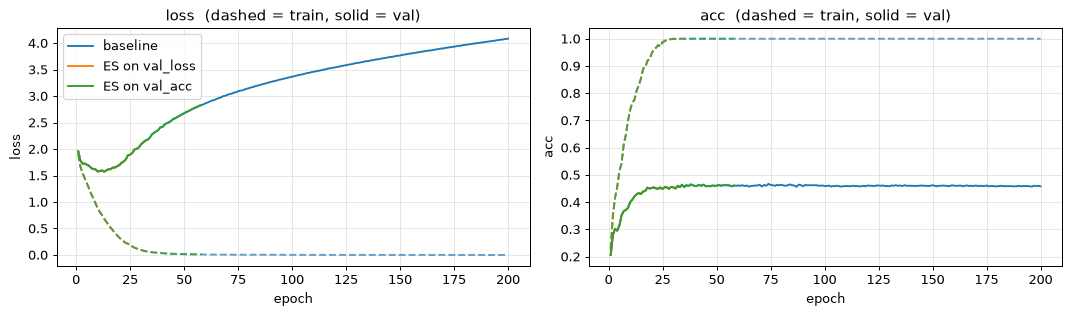

In [28]:
# Summary for 3.3
rows = {}
for monitor, h in es_hists.items():
    vl, va = evaluate(es_models[monitor], DATA["X_val"], DATA["y_val"], F.cross_entropy)
    rows[f"monitor = {monitor}"] = dict(stopped_at=h["epoch"][-1], best_epoch=es_callbacks[monitor].best_epoch,
                                         val_loss=vl, val_acc=va)
rows["no early stopping (200 epochs)"] = dict(stopped_at=200, best_epoch=200,
                                              val_loss=hist_baseline["val_loss"][-1], val_acc=hist_baseline["val_acc"][-1])
display(pd.DataFrame(rows).T.round(3))
plot_histories({"baseline": hist_baseline, **{f"ES on {k}": h for k, h in es_hists.items()}})

In [29]:
# Tests for 3.3 (implementation)
assert set(es_hists) == {"val_loss", "val_acc"}
assert es_callbacks["val_loss"].monitor == "val_loss" and es_callbacks["val_acc"].mode == "max"
for _k, _cb in es_callbacks.items():
    _vl, _va = evaluate(es_models[_k], DATA["X_val"], DATA["y_val"], F.cross_entropy)
    assert np.isclose({"val_loss": _vl, "val_acc": _va}[_k], _cb.best_value, atol=1e-4), "the best weights were not restored"
assert "early stopping" in RESULTS
print("3.3 tests passed")
# Sanity checks (results)
expect(es_hists["val_loss"]["epoch"][-1] < 200, "early stopping on val_loss stops well before 200 epochs")
expect(es_callbacks["val_loss"].best_epoch < es_callbacks["val_acc"].best_epoch, "the val_loss optimum comes earlier than the val_acc optimum")

3.3 tests passed
✓ early stopping on val_loss stops well before 200 epochs
✓ the val_loss optimum comes earlier than the val_acc optimum


> (a) The two monitors stop at very different epochs. Which model has the better validation loss, which the better accuracy, and why do the metrics disagree?
> (b) What did early stopping buy compared with the baseline, and what did it cost?

**(a)** Monitoring `val_loss` stops at epoch 33 and returns the epoch-13 model: validation loss **1.573** but accuracy only 0.429. Monitoring `val_acc` stops at epoch 58 and returns the epoch-38 model: accuracy **0.465** but loss 2.356. So the `val_loss` model has the better loss and the `val_acc` model the better accuracy. The two disagree because after about epoch 13 the network keeps fitting the training set and becomes more confident everywhere. On validation examples it gets wrong, that confidence grows, and their loss grows without bound, so the mean loss goes up. Meanwhile some borderline examples still move to the correct side of the decision boundary, so the accuracy creeps up for another 25 epochs. Loss measures confidence, accuracy only counts the argmax.

**(b)** Compared with the baseline (val acc 0.458, val loss 4.08 after 200 epochs), early stopping on `val_acc` gave about the same accuracy (0.465, less than 1 point better) but a much lower loss (2.36), and stopping on `val_loss` cut the loss even more (1.57). It also saved compute: 58 or 33 epochs instead of 200, i.e. 70 to 85% less training. The costs: we need a held-out validation set (here 1000 examples that are not used for training, as many as the training set itself), we evaluate it every epoch, the result depends on the patience and on which metric we monitor, and it does not shrink the generalization gap the way L2 or dropout do. The training accuracy at the chosen epochs is already almost 100%.

---
## 4. Dropout from scratch

Dropout written by hand, backward pass included, and a test of the explanation that dropout trains an ensemble of $2^M$ weight-sharing sub-networks.

*"In each forward pass, randomly set some neurons to zero."* Each unit is kept with probability $p$ (`keep_prob`,
called $\alpha$ in the lecture). We use **inverted dropout**: during training the kept activations are divided by
$p$, so that the expected activation is unchanged and nothing has to be done at test time.

* **4-A (NumPy):** the forward *and backward* pass of an MLP with dropout by hand (the *Backward
  Pass* slide) verified with a numerical gradient check.
* **4-B (PyTorch):** dropout as an `nn.Module` on MNIST-1D, and a test of the
  *"dropout = an ensemble of $2^M$ sub-networks"* view with Monte-Carlo averaging.

### 4-A · NumPy

Conventions: a batch is a matrix `X` of shape `(N, D)`, weights have shape `(fan_in, fan_out)`, so a layer computes
`X @ W + b`. Everything is `float64` so that the gradient check is precise. The loss (softmax cross-entropy, mean over
the batch), its gradient w.r.t. the logits, and the inverted-dropout mask are defined first.

In [30]:
def softmax_cross_entropy(logits, y):
    """Mean cross-entropy and its gradient w.r.t. the logits."""
    z = logits - logits.max(axis=1, keepdims=True)
    logp = z - np.log(np.exp(z).sum(axis=1, keepdims=True))
    n = len(y)
    loss = -logp[np.arange(n), y].mean()
    dlogits = np.exp(logp)
    dlogits[np.arange(n), y] -= 1
    return loss, dlogits / n


def rel_error(a, b):
    a, b = np.asarray(a, dtype=np.float64), np.asarray(b, dtype=np.float64)
    return float(np.max(np.abs(a - b) / np.maximum(1e-8, np.abs(a) + np.abs(b))))


def dropout_mask(shape, keep_prob, rng):
    """Inverted-dropout mask: 1/keep_prob with probability keep_prob, 0 otherwise."""
    return (rng.random(shape) < keep_prob) / keep_prob

#### 4.1 Forward and backward pass

The network is `X → Linear → ReLU → Dropout → Linear → ReLU → Dropout → Linear → logits`. With $m^{[l]}$ the mask of layer $l$:

$$z^{[1]} = X W_1 + b_1,\quad a^{[1]} = \mathrm{ReLU}(z^{[1]}) \odot m^{[1]},\quad
  z^{[2]} = a^{[1]} W_2 + b_2,\quad a^{[2]} = \mathrm{ReLU}(z^{[2]}) \odot m^{[2]},\quad
  \text{logits} = a^{[2]} W_3 + b_3 .$$

* `forward(X, train=True, masks=None, rng=None)` uses the given `masks = (m1, m2)` in training mode, or draws new ones with `dropout_mask`. In evaluation mode (`train=False`) no dropout is applied. It returns the logits and a `cache` dict for `backward`.
* `backward(cache, dlogits)` returns the gradients of all six parameters, with the same keys and shapes as `self.params`. Gradients flow only through the units that were kept.

In [31]:
class NumpyDropoutMLP:
    def __init__(self, in_dim, hidden, out_dim, keep_prob=0.5, seed=0):
        rng = np.random.default_rng(seed)
        self.keep_prob = keep_prob
        self.params = {
            "W1": rng.standard_normal((in_dim, hidden)) * np.sqrt(2 / in_dim), "b1": np.zeros(hidden),
            "W2": rng.standard_normal((hidden, hidden)) * np.sqrt(2 / hidden), "b2": np.zeros(hidden),
            "W3": rng.standard_normal((hidden, out_dim)) * np.sqrt(1 / hidden), "b3": np.zeros(out_dim),
        }

    def _mask(self, shape, train, masks, layer, rng):
        if not train:
            return np.ones(shape)                 # evaluation: no dropout
        if masks is not None:
            return masks[layer]
        return dropout_mask(shape, self.keep_prob, rng)

    def forward(self, X, train=True, masks=None, rng=None):
        p = self.params
        rng = np.random.default_rng() if rng is None else rng
        z1 = X @ p["W1"] + p["b1"]
        m1 = self._mask(z1.shape, train, masks, 0, rng)
        a1 = np.maximum(z1, 0) * m1
        z2 = a1 @ p["W2"] + p["b2"]
        m2 = self._mask(z2.shape, train, masks, 1, rng)
        a2 = np.maximum(z2, 0) * m2
        logits = a2 @ p["W3"] + p["b3"]
        cache = dict(X=X, z1=z1, m1=m1, a1=a1, z2=z2, m2=m2, a2=a2)
        return logits, cache

    def backward(self, cache, dlogits):
        p = self.params
        grads = {}
        grads["W3"] = cache["a2"].T @ dlogits
        grads["b3"] = dlogits.sum(axis=0)
        da2 = dlogits @ p["W3"].T
        dz2 = da2 * cache["m2"] * (cache["z2"] > 0)   # only kept and active units pass the gradient
        grads["W2"] = cache["a1"].T @ dz2
        grads["b2"] = dz2.sum(axis=0)
        da1 = dz2 @ p["W2"].T
        dz1 = da1 * cache["m1"] * (cache["z1"] > 0)
        grads["W1"] = cache["X"].T @ dz1
        grads["b1"] = dz1.sum(axis=0)
        return grads

In [32]:
# Tests for 4.1 (shapes, evaluation mode, and dropped units)
_Xn = DATA["X_train"][:8].double().numpy()
_yn = DATA["y_train"][:8].numpy()
_net = NumpyDropoutMLP(40, 16, 10, keep_prob=0.5, seed=1)
_logits, _cache = _net.forward(_Xn, train=True, rng=np.random.default_rng(0))
_grads = _net.backward(_cache, softmax_cross_entropy(_logits, _yn)[1])
assert _logits.shape == (8, 10)
assert set(_grads) == set(_net.params) and all(_grads[k].shape == _net.params[k].shape for k in _grads)
_e1, _ = _net.forward(_Xn, train=False); _e2, _ = _net.forward(_Xn, train=False)
assert np.array_equal(_e1, _e2), "evaluation mode must be deterministic (no dropout)"
_m = (np.ones((1, 16)), np.ones((1, 16)))
_m[0][0, :8] = 0                                            # drop units 0..7 of layer 1 for a single example
_l, _c = _net.forward(_Xn[:1], train=True, masks=_m)
_g = _net.backward(_c, softmax_cross_entropy(_l, _yn[:1])[1])
assert np.all(_g["W1"][:, :8] == 0) and np.all(_g["b1"][:8] == 0), "incoming weights of a dropped unit must get zero gradient"
assert np.all(_g["W2"][:8, :] == 0), "outgoing weights of a dropped unit must get zero gradient"
print("4.1 tests passed")

4.1 tests passed


#### 4.2 Gradient check

`grad_check(model, X, y, masks, num_checks=10, h=1e-5)` computes the analytic gradients with the given masks, then, for `num_checks` random entries of every parameter, the centred finite difference
$$\frac{\partial J}{\partial \theta_i} \approx \frac{J(\theta_i + h) - J(\theta_i - h)}{2h},$$
restoring each entry afterwards. It returns the largest `rel_error`. The loss is evaluated with the same masks as the analytic gradient.

In [33]:
def grad_check(model, X, y, masks, num_checks=10, h=1e-5, seed=0):
    rng = np.random.default_rng(seed)

    def loss_now():
        logits, _ = model.forward(X, train=True, masks=masks)
        return softmax_cross_entropy(logits, y)[0]

    logits, cache = model.forward(X, train=True, masks=masks)
    grads = model.backward(cache, softmax_cross_entropy(logits, y)[1])

    worst = 0.0
    for name, param in model.params.items():
        for _ in range(num_checks):
            i = np.unravel_index(rng.integers(param.size), param.shape)
            old = param[i]
            param[i] = old + h
            loss_plus = loss_now()
            param[i] = old - h
            loss_minus = loss_now()
            param[i] = old                       # restore the entry
            numeric = (loss_plus - loss_minus) / (2 * h)
            worst = max(worst, rel_error(numeric, grads[name][i]))
    return worst

In [34]:
# Tests for 4.2
_rng = np.random.default_rng(0)
_masks = (dropout_mask((8, 16), 0.5, _rng), dropout_mask((8, 16), 0.5, _rng))
_err = grad_check(_net, _Xn, _yn, _masks)
print(f"max relative error with fixed masks: {_err:.2e}")
assert _err < 1e-6, "the backward pass (or the gradient check) is wrong"

# Cross-check against PyTorch autograd with the same masks
_P = {k: torch.tensor(v, requires_grad=True) for k, v in _net.params.items()}
_a1 = torch.relu(torch.tensor(_Xn) @ _P["W1"] + _P["b1"]) * torch.tensor(_masks[0])
_a2 = torch.relu(_a1 @ _P["W2"] + _P["b2"]) * torch.tensor(_masks[1])
F.cross_entropy(_a2 @ _P["W3"] + _P["b3"], torch.tensor(_yn)).backward()
_logits, _cache = _net.forward(_Xn, train=True, masks=_masks)
_grads = _net.backward(_cache, softmax_cross_entropy(_logits, _yn)[1])
for _k in _P:
    assert rel_error(_grads[_k], _P[_k].grad.numpy()) < 1e-8, f"gradient of {_k} differs from autograd"
print("4.2 tests passed: NumPy backward == numerical gradient == PyTorch autograd")

max relative error with fixed masks: 8.96e-07
4.2 tests passed: NumPy backward == numerical gradient == PyTorch autograd


The same check, but with **new** masks drawn every time the loss is evaluated:

In [35]:
print(f"max relative error with re-sampled masks: {grad_check(_net, _Xn, _yn, masks=None):.2e}")

max relative error with re-sampled masks: 1.00e+00


> Why does the gradient check fail completely when the masks are re-sampled, although the backward pass is correct? What is the training gradient an estimate of?

With re-sampled masks, the two loss evaluations $J(\theta_i + h)$ and $J(\theta_i - h)$ are computed with two *different* random sub-networks. The difference between the losses of two random sub-networks is of order $0.1$ to $1$, and it has nothing to do with the tiny change $h$ in one parameter. Dividing it by $2h = 2\cdot10^{-5}$ gives an enormous number unrelated to the true derivative, so the relative error is 1.00, the maximum possible.

With dropout, the loss is no longer a fixed function of $\theta$: it is a random variable $J(\theta, m)$ that also depends on the mask $m$. That is what the lecture means by "the cost function is no longer well defined". What we minimize is the expected loss over all $2^M$ sub-networks, $\mathbb E_m[J(\theta, m)]$. The gradient we compute in a training step is the gradient of $J(\theta, m)$ for one sampled mask, and because the mask distribution does not depend on $\theta$, $\mathbb E_m[\nabla_\theta J(\theta, m)] = \nabla_\theta \mathbb E_m[J(\theta, m)]$. So the training gradient is an unbiased, noisy estimate of the gradient of the expected loss, just as a mini-batch gradient estimates the full-data gradient. To check it numerically we must fix $m$, which turns $J$ back into a deterministic function.

### 4-B · PyTorch

#### 4.3 An inverted-dropout module

`InvertedDropout` is an `nn.Module`. In training mode it multiplies its input by a fresh 0/1 mask divided by `keep_prob`; in evaluation mode it returns the input unchanged.

In [36]:
class InvertedDropout(nn.Module):
    def __init__(self, keep_prob=0.5):
        super().__init__()
        self.keep_prob = keep_prob

    def forward(self, x):
        if not self.training:
            return x
        mask = (torch.rand_like(x) < self.keep_prob).float()
        return x * mask / self.keep_prob

In [37]:
# Tests for 4.3
torch.manual_seed(0)
_x = torch.ones(20000, 50)
_d = InvertedDropout(0.7).train()
_o = _d(_x)
assert abs((_o == 0).float().mean().item() - 0.3) < 0.01, "wrong fraction of dropped units"
assert torch.allclose(_o[_o != 0], torch.tensor(1 / 0.7)), "kept units must be scaled by 1/keep_prob"
assert abs(_o.mean().item() - 1.0) < 0.01, "the expected activation must be unchanged in training"
assert not torch.equal(_o, _d(_x)), "a new mask must be drawn at every forward pass"
assert torch.equal(_d.eval()(_x[:5]), _x[:5]), "evaluation mode must return the input unchanged"
_xg = torch.randn(100, 30, requires_grad=True)
_d = InvertedDropout(0.5).train()
_o = _d(_xg); _o.sum().backward()
assert torch.all((_xg.grad == 0) == (_o == 0)), "gradient must be zero exactly for the dropped units"
assert torch.allclose(_xg.grad[_o != 0], torch.tensor(2.0)), "kept units: gradient 1/keep_prob"
assert torch.equal(InvertedDropout(1.0).train()(_x[:3]), _x[:3]), "keep_prob = 1 must be the identity"
print("4.3 tests passed")

4.3 tests passed


#### 4.4 Dropout on MNIST-1D

For every `keep_prob` in `KEEP_PROBS`, a fresh `make_mlp(**MLP, dropout=lambda: InvertedDropout(keep_prob))` trains from the same seed (the `lambda` has to capture the current `keep_prob`). `best_keep` is chosen by the final validation accuracy and goes on the leaderboard. *(≈ 30 s)*

In [38]:
KEEP_PROBS = [1.0, 0.8, 0.5, 0.3]
drop_hists, drop_models = {}, {}
for keep_prob in KEEP_PROBS:
    seed_everything(SEED)
    # kp=keep_prob freezes the current value, so every model gets its own keep_prob
    model = make_mlp(**MLP, dropout=lambda kp=keep_prob: InvertedDropout(kp))
    drop_hists[keep_prob] = train_model(model, DATA["X_train"], DATA["y_train"], **CLF,
                                        X_val=DATA["X_val"], y_val=DATA["y_val"])
    drop_models[keep_prob] = model

best_keep = max(KEEP_PROBS, key=lambda kp: drop_hists[kp]["val_acc"][-1])
record_result(f"dropout (keep={best_keep})", drop_models[best_keep])

[dropout (keep=0.5)] val acc 0.537 | val loss 1.847


,train acc,val acc,val loss
1.0,1.00,0.469,4.071
0.8,1.00,0.506,2.898
0.5,1.00,0.537,1.847
0.3,0.94,0.534,1.406


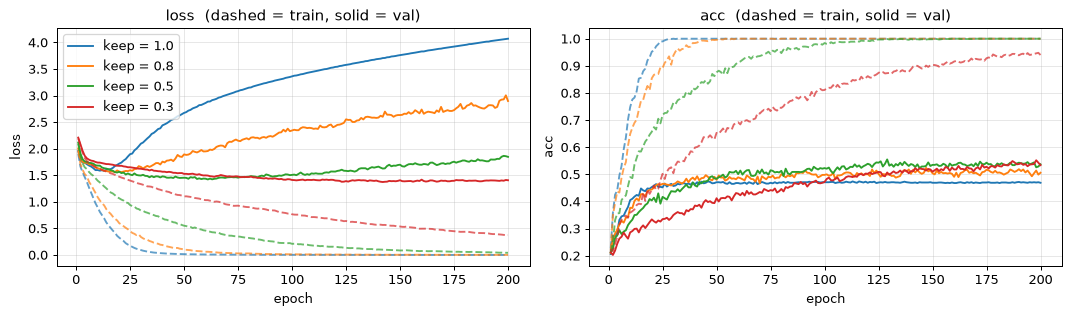

In [39]:
# Summary for 4.4
display(pd.DataFrame({kp: {"train acc": h["train_acc"][-1], "val acc": h["val_acc"][-1], "val loss": h["val_loss"][-1]}
                      for kp, h in drop_hists.items()}).T.round(3))
plot_histories({f"keep = {kp}": h for kp, h in drop_hists.items()})

In [40]:
# Tests for 4.4 (implementation)
assert set(drop_hists) == set(KEEP_PROBS)
assert all(drop_models[kp][2].keep_prob == kp for kp in KEEP_PROBS), "closure bug: every model must use its own keep_prob"
assert best_keep == max(KEEP_PROBS, key=lambda kp: drop_hists[kp]["val_acc"][-1])
assert f"dropout (keep={best_keep})" in RESULTS
print("4.4 tests passed")
# Sanity check (results)
expect(drop_hists[best_keep]["val_acc"][-1] > drop_hists[1.0]["val_acc"][-1] + 0.03, "dropout clearly beats no dropout here")

4.4 tests passed
✓ dropout clearly beats no dropout here


> How does the keep probability affect (a) the training curves and (b) the generalization gap, validation accuracy and validation loss? Why does too much dropout hurt? (c) Why is *inverted* dropout preferred over scaling by `keep_prob` at test time?

**(a)** The lower the keep probability, the slower the network fits the training set. Without dropout it reaches 100% train accuracy by about epoch 25, with keep 0.8 by about epoch 40, with 0.5 only around epoch 125, and with keep 0.3 it is still at 0.94 after 200 epochs. The training loss falls more slowly in the same order.

**(b)** The gap and the validation loss shrink as the keep probability drops. Validation accuracy: 0.469, 0.506, 0.537, 0.534 (gap from 53 points down to 41). Validation loss: 4.07, 2.90, 1.85, 1.41. Without dropout the validation loss rises steadily after epoch 15, while with keep 0.3 it stays flat. Too much dropout hurts because every unit sees only a small random part of its inputs. With keep 0.3, each forward pass uses about 77 of the 256 units per layer, and the noise in the activations becomes so large that the network can no longer fit the data well. That shows in the train accuracy of 0.94, and the validation accuracy has already stopped improving (0.534 < 0.537). Going further, the model would under-fit.

**(c)** With inverted dropout the scaling happens during training, so the test-time network is the plain network: no change to the inference code, no need to remember `keep_prob` when deploying, and the same model can be used with or without dropout layers. It also keeps the expected activation the same in training and testing, so the scale of every layer's input does not depend on `keep_prob`, and changing `keep_prob` (even per layer, or during training) does not change the scale of the following layers or how the learning rate interacts with them.

#### 4.5 Dropout as an ensemble: Monte-Carlo averaging

At test time, inverted dropout uses the *expected* activation of each unit (the *weight-scaling* rule). The ensemble view
suggests another option: keep dropout **on** at test time, run $T$ stochastic forward passes (= $T$ random
sub-networks) and average their predicted probabilities. `mc_dropout_predict(model, X, T)` returns these averaged class probabilities, shape `(N, C)`, and restores the model's original mode afterwards.

In [41]:
def mc_dropout_predict(model, X, T):
    was_training = model.training
    model.train()                          # keep dropout on
    total = 0
    with torch.no_grad():
        for _ in range(T):
            total = total + F.softmax(model(X), dim=1)
    model.train(was_training)
    return total / T

In [42]:
# Tests for 4.5
_mdl = drop_models[best_keep].eval()
_p = mc_dropout_predict(_mdl, DATA["X_val"][:50], T=5)
assert _p.shape == (50, 10) and torch.allclose(_p.sum(1), torch.ones(50), atol=1e-5)
assert not _mdl.training, "restore the original mode"
assert not torch.allclose(_p, mc_dropout_predict(_mdl, DATA["X_val"][:50], T=5)), "dropout must be active inside"
with torch.no_grad():
    _ref = F.softmax(drop_models[1.0].eval()(DATA["X_val"][:50]), 1)
assert torch.allclose(mc_dropout_predict(drop_models[1.0], DATA["X_val"][:50], T=3), _ref, atol=1e-6), \
    "without dropout, MC averaging must equal the deterministic prediction"
print("4.5 tests passed")

4.5 tests passed


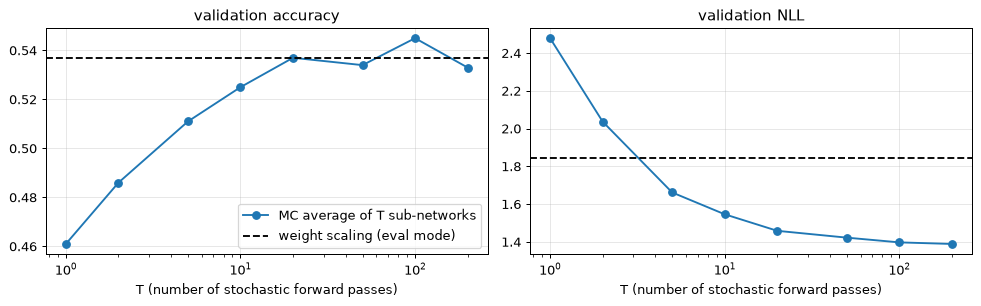

In [43]:
# MC averaging vs weight scaling
mdl = drop_models[best_keep]
yv = DATA["y_val"]
with torch.no_grad():
    mdl.eval()
    p_ws = F.softmax(mdl(DATA["X_val"]), 1)
ws_acc, ws_nll = (p_ws.argmax(1) == yv).float().mean().item(), F.nll_loss(p_ws.log(), yv).item()
Ts, mc_acc, mc_nll = [1, 2, 5, 10, 20, 50, 100, 200], [], []
torch.manual_seed(SEED)
for T in Ts:
    p = mc_dropout_predict(mdl, DATA["X_val"], T)
    mc_acc.append((p.argmax(1) == yv).float().mean().item()); mc_nll.append(F.nll_loss(p.clamp_min(1e-12).log(), yv).item())
fig, axs = plt.subplots(1, 2, figsize=(11, 3.5))
axs[0].plot(Ts, mc_acc, "o-", label="MC average of T sub-networks"); axs[0].axhline(ws_acc, c="k", ls="--", label="weight scaling (eval mode)")
axs[1].plot(Ts, mc_nll, "o-"); axs[1].axhline(ws_nll, c="k", ls="--")
axs[0].set_title("validation accuracy"); axs[1].set_title("validation NLL"); axs[0].legend()
for ax in axs:
    ax.set_xscale("log"); ax.set_xlabel("T (number of stochastic forward passes)")
plt.tight_layout(); plt.show()

> (a) How does a single stochastic pass ($T = 1$) compare with weight scaling, and what happens as $T$ grows?
> (b) For a single linear layer, weight scaling reproduces the expected pre-softmax output exactly, but not the average predicted probabilities. Why, and what do more nonlinear layers do?
> (c) Which method would I use in a deployed model?

**(a)** A single stochastic pass is much worse than weight scaling: validation accuracy 0.461 against 0.537, and NLL 2.48 against 1.85. One pass is just one random sub-network, with about half of its units missing. As $T$ grows, the accuracy climbs and reaches the weight-scaling level at $T \approx 20$ (0.537), then fluctuates around it (0.545 at $T = 100$, 0.533 at $T = 200$). The NLL falls below weight scaling already at $T = 5$ (1.66) and keeps falling, to about 1.39 at $T = 200$. So the MC average of many sub-networks matches weight scaling in accuracy and gives clearly better probabilities.

**(b)** For a linear layer $z = W(m \odot x)/p$, linearity of expectation gives $\mathbb E_m[z] = W x$, exactly what weight scaling computes. But the predicted probabilities are $\mathrm{softmax}(z)$, a non-linear function, and $\mathbb E[\mathrm{softmax}(z)] \neq \mathrm{softmax}(\mathbb E[z])$ in general (Jensen). Weight scaling gives the softmax of the mean logits, which for a single softmax layer is the normalized *geometric* mean of the sub-networks' probabilities. MC averaging computes the *arithmetic* mean. With more non-linear layers even the expected logits are no longer reproduced, because $\mathbb E[\mathrm{ReLU}(z)] \neq \mathrm{ReLU}(\mathbb E[z])$, so every hidden layer adds approximation error and weight scaling becomes a heuristic. It works well in practice, and here it gives the same accuracy.

**(c)** For a deployed model I would use weight scaling: it needs one deterministic forward pass instead of $T$, it is reproducible, and here it is just as accurate. I would use MC dropout (with $T$ around 10 to 20) only when calibrated probabilities or an uncertainty estimate matter enough to pay $T$ times the inference cost, since that is where it is clearly better (lower NLL).

---
## 5. Ensembles and bagging

Why averaging models helps (variance reduction, diverse members), and what it costs compared with dropout's free ensemble.

*"Train multiple models, and at test time average their predictions."* Two ways to make the members different:
* **different initializations** (and mini-batch orders): same data, different random seeds;
* **bagging** (Breiman): each member is trained on a *bootstrap sample* — $N$ examples drawn **with replacement** from
  the $N$ training examples.

And three ways to combine $K$ classifiers: average the **logits** (pre-softmax activations), average the
**probabilities**, or take a **majority vote** of the predicted classes.

### 5.1 Training an ensemble

`train_ensemble(K, data, bootstrap=False, seed0=0)` trains member `k` from seed `seed0 + k`. With `bootstrap`, each member trains on `n` indices drawn uniformly with replacement. The members are fresh `make_mlp(**MLP)` models trained without a validation set.

In [44]:
def train_ensemble(K, data, bootstrap=False, seed0=0):
    X, y = data["X_train"], data["y_train"]
    n = len(X)
    models = []
    for k in range(K):
        seed_everything(seed0 + k)
        if bootstrap:
            idx = torch.randint(0, n, (n,))     # n draws with replacement
            Xk, yk = X[idx], y[idx]
        else:
            Xk, yk = X, y
        model = make_mlp(**MLP)
        train_model(model, Xk, yk, **CLF)
        models.append(model)
    return models

### 5.2 Combining the members

`ensemble_predict(models, X, method)` returns the predicted class of every example, for `method` in `"logits"` (argmax of the mean logits), `"probs"` (argmax of the mean softmax probabilities) and `"vote"` (most frequent predicted class; `torch.mode` breaks ties towards the smallest class index).

In [45]:
def ensemble_predict(models, X, method="probs"):
    outputs = []
    with torch.no_grad():
        for m in models:
            m.eval()
            outputs.append(m(X))
    logits = torch.stack(outputs)            # (K, N, C)
    if method == "logits":
        return logits.mean(dim=0).argmax(dim=1)
    if method == "probs":
        return F.softmax(logits, dim=2).mean(dim=0).argmax(dim=1)
    if method == "vote":
        votes = logits.argmax(dim=2)         # (K, N)
        return torch.mode(votes, dim=0).values
    raise ValueError(f"unknown method {method}")

In [46]:
# Tests for 5.2 — hand-made "models" with constant outputs, chosen so that the three methods disagree
class _Const(nn.Module):
    def __init__(self, logits):
        super().__init__()
        self.logits = torch.tensor(logits, dtype=torch.float32)

    def forward(self, X):
        return self.logits.expand(len(X), -1)

_X2 = torch.zeros(4, 40)
# Case A: one member is extremely sure that class 0 is wrong -> averaging logits is dominated by it
_A = [_Const([-20., 0., 0.]), _Const([2., 0., 0.]), _Const([2., 0., 0.])]
# Case B: one very confident member vs. two weak members -> the vote differs from the averages
_B = [_Const([5., 0., 0.]), _Const([0., .1, 0.]), _Const([0., .1, 0.])]
for _models, _expected in [(_A, dict(logits=1, probs=0, vote=0)), (_B, dict(logits=0, probs=0, vote=1))]:
    for _method, _cls in _expected.items():
        _pred = ensemble_predict(_models, _X2, _method)
        assert _pred.shape == (4,) and torch.all(_pred == _cls), f"method={_method}: expected class {_cls}, got {_pred.tolist()}"
print("5.2 tests passed")

5.2 tests passed


### 5.3 Experiments

Two ensembles of `K_ENS` members on `DATA`: `ens_seeds` (different seeds, full data) and `ens_bag` (bootstrap samples), both with `seed0=100` so that the members differ from the models of earlier sections. *(≈ 3 min, the slowest cell of the notebook)*

In [47]:
K_ENS = 10
ens_seeds = train_ensemble(K_ENS, DATA, bootstrap=False, seed0=100)
ens_bag = train_ensemble(K_ENS, DATA, bootstrap=True, seed0=100)

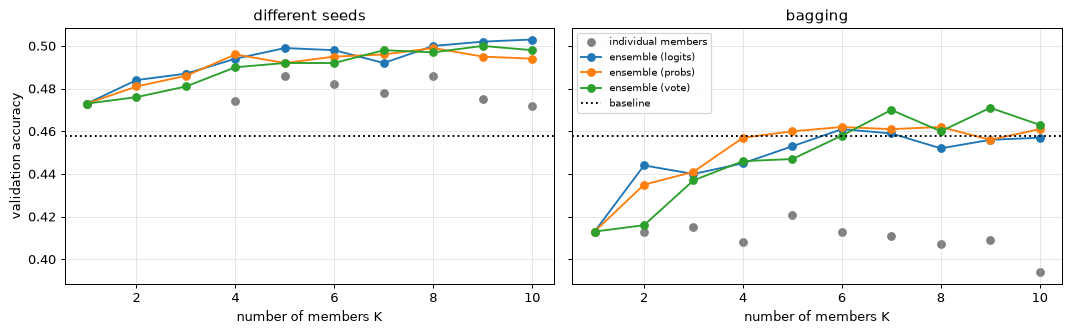

[ensemble (10 seeds)] val acc 0.494 | val loss 2.838
[bagging (10 bootstraps)] val acc 0.461 | val loss 2.347


In [48]:
# Accuracy vs ensemble size, for both kinds of ensembles and all combination methods
class EnsembleModel(nn.Module):
    """Wraps a list of models; returns the log of the averaged probabilities (so cross-entropy = ensemble NLL)."""
    def __init__(self, models):
        super().__init__()
        self.members = nn.ModuleList(models)

    def forward(self, X):
        return torch.stack([F.softmax(m(X), 1) for m in self.members]).mean(0).clamp_min(1e-12).log()


def acc(pred, y):
    return (pred == y).float().mean().item()

Xv, yv = DATA["X_val"], DATA["y_val"]
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
ens_curves = {}
for ax, (name, members) in zip(axs, [("different seeds", ens_seeds), ("bagging", ens_bag)]):
    singles = [acc(ensemble_predict([m], Xv), yv) for m in members]
    ax.scatter(range(1, K_ENS + 1), singles, c="0.5", label="individual members")
    for method in ["logits", "probs", "vote"]:
        curve = [acc(ensemble_predict(members[:k], Xv, method), yv) for k in range(1, K_ENS + 1)]
        ens_curves[(name, method)] = curve
        ax.plot(range(1, K_ENS + 1), curve, "o-", label=f"ensemble ({method})")
    ax.axhline(RESULTS["baseline"]["val_acc"], c="k", ls=":", label="baseline")
    ax.set_title(name); ax.set_xlabel("number of members K")
axs[0].set_ylabel("validation accuracy"); axs[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

record_result(f"ensemble ({K_ENS} seeds)", EnsembleModel(ens_seeds))
record_result(f"bagging ({K_ENS} bootstraps)", EnsembleModel(ens_bag))

In [49]:
# Tests for 5.3 (implementation)
assert len(ens_seeds) == len(ens_bag) == K_ENS
assert len({id(m) for m in ens_seeds + ens_bag}) == 2 * K_ENS, "every member must be a separately trained model"
print("5.3 tests passed")
# Sanity checks (results)
_single_bag = np.mean([acc(ensemble_predict([m], Xv), yv) for m in ens_bag])
_single_seed = np.mean([acc(ensemble_predict([m], Xv), yv) for m in ens_seeds])
expect(_single_bag < _single_seed, "bootstrap members (fewer distinct examples) are individually weaker")
expect(ens_curves[("different seeds", "probs")][-1] > _single_seed, "the ensemble beats its average member")

5.3 tests passed
✓ bootstrap members (fewer distinct examples) are individually weaker
✓ the ensemble beats its average member


> (a) What fraction of the distinct training examples does a bootstrap sample contain on average? Why are the bagged members weaker, yet the bagged ensemble gains more over its members than the seed ensemble?
> (b) Why does the gain flatten as $K$ grows, for $K$ correlated predictors with variance $\sigma^2$ and pairwise correlation $\rho$?
> (c) How do ensembles compare with dropout in training cost, test cost and accuracy?

**(a)** In one draw a given example is missed with probability $1 - \frac1N$, so in $N$ independent draws it is never drawn with probability $(1 - \frac1N)^N \to e^{-1} \approx 0.368$. A bootstrap sample therefore contains on average $1 - e^{-1} \approx 63.2\%$ of the distinct examples (632 of our 1000), and the rest of it is duplicates. Each bagged member learns from about a third less information, so it is weaker: the bagged members score about 0.39 to 0.42 on validation, against about 0.47 to 0.49 for the seed members. But since each member saw a different subset, their mistakes are less alike, and averaging cancels more of them. The bagged ensemble gains about 5 points over its average member (about 0.41 to 0.461), while the seed ensemble gains only about 1.5 points (about 0.478 to 0.494). In absolute terms the seed ensemble still wins here, because with only 1000 examples losing 37% of the data costs more than the extra diversity brings back.

**(b)** For $K$ predictors with variance $\sigma^2$ and pairwise correlation $\rho$,
$$\mathrm{Var}\Big(\frac1K\sum_k f_k\Big) = \rho\,\sigma^2 + \frac{1 - \rho}{K}\,\sigma^2 .$$
Only the second term shrinks with $K$. The first, $\rho\sigma^2$, is a floor that no number of members removes. Our members are strongly correlated (same architecture, same data or overlapping data, same training recipe), so most of the gain comes from the first few members: the seed ensemble is at 0.499 with 5 members and only at 0.503 (logits) with 10. Lowering $\rho$ (more diverse members) helps more than adding members.

**(c)** Training cost: an ensemble of $K$ costs $K$ full trainings (10 here); dropout costs one training, a bit slower to converge. Test cost: an ensemble needs $K$ forward passes and $K$ times the memory; dropout with weight scaling needs one pass. Accuracy: on this problem dropout was better as well as cheaper (0.537 for keep 0.5, against 0.494 for the seed ensemble and 0.461 for bagging). Dropout's $2^M$ sub-networks share weights, so each one is also regularized during training, while each ensemble member is an unregularized network that over-fits on its own. The two can also be combined (an ensemble of dropout networks), as in Section 8.

---
## 6. Noise on inputs and labels

Two kinds of noise injection. Label-preserving noise on the inputs (data augmentation) adds information about invariances and should improve accuracy. Noise on the labels (label smoothing) fights over-confidence and should improve calibration.

Both plug into `train_model`: augmentation through the `batch_transform` hook, label smoothing through `loss_fn`.

### 6.1 Noise on the inputs: data augmentation

An MNIST-1D digit is still the same digit if it is **shifted** by a few positions, slightly **rescaled** in amplitude, or
corrupted with a little noise. `augment_mnist1d(xb, yb, max_shift=6, scale=0.2, noise=0.1)` applies,
independently to every example of the batch:
1. a circular shift (`torch.roll`-like) by a random integer $s \in \{-\text{max\_shift}, \dots, \text{max\_shift}\}$ (vectorized with an index matrix `(arange(L) - s[:, None]) % L` and `torch.gather`);
2. multiplication by a random factor uniform in $[1 - \text{scale}, 1 + \text{scale}]$;
3. additive Gaussian noise with standard deviation `noise`.

The labels are returned unchanged.

In [50]:
def augment_mnist1d(xb, yb, max_shift=6, scale=0.2, noise=0.1):
    N, L = xb.shape
    # 1. circular shift: out[n, i] = x[n, (i - s_n) mod L], the same as torch.roll by s_n
    shifts = torch.randint(-max_shift, max_shift + 1, (N,))
    idx = (torch.arange(L)[None, :] - shifts[:, None]) % L
    out = torch.gather(xb, 1, idx)
    # 2. amplitude factor uniform in [1 - scale, 1 + scale]
    factors = 1 + scale * (2 * torch.rand(N, 1) - 1)
    out = out * factors
    # 3. additive Gaussian noise
    out = out + noise * torch.randn_like(out)
    return out, yb

In [51]:
# Tests for 6.1
torch.manual_seed(0)
_xa = DATA["X_train"][:200]
_xs, _ys = augment_mnist1d(_xa, DATA["y_train"][:200], max_shift=4, scale=0.0, noise=0.0)
assert _xs.shape == _xa.shape and torch.equal(_ys, DATA["y_train"][:200])
_shifts = []
for _i in range(200):
    _ok = [s for s in range(-4, 5) if torch.allclose(_xs[_i], torch.roll(_xa[_i], s))]
    assert _ok, f"example {_i} is not a circular shift of the original by at most 4"
    _shifts.append(_ok[0])
assert len(set(_shifts)) > 5, "every example must get its own random shift"
_xs2, _ = augment_mnist1d(_xa, DATA["y_train"][:200], max_shift=0, scale=0.2, noise=0.0)
_ratio = (_xs2 / _xa)[_xa.abs() > 0.1]
assert 0.79 < _ratio.min() and _ratio.max() < 1.21 and _ratio.std() > 0.05, "amplitude scaling is wrong"
print("6.1 tests passed")

6.1 tests passed


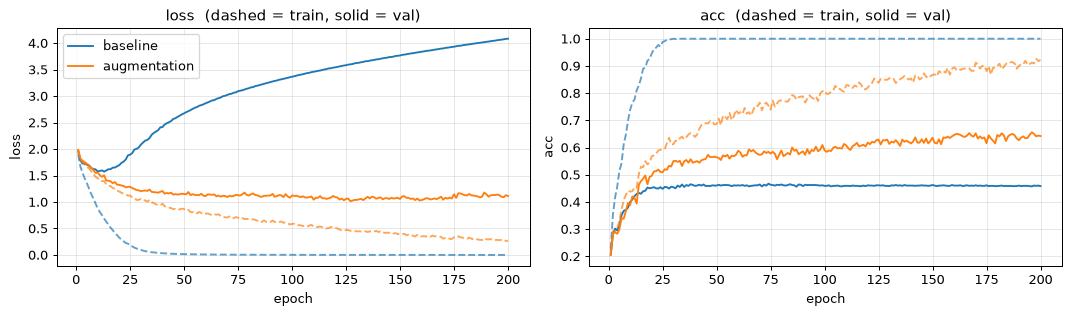

[data augmentation] val acc 0.642 | val loss 1.113


In [52]:
# Training with augmentation (≈ 10 s)
seed_everything(SEED)
aug_model = make_mlp(**MLP)
hist_aug = train_model(aug_model, DATA["X_train"], DATA["y_train"], **CLF, batch_transform=augment_mnist1d,
                       X_val=DATA["X_val"], y_val=DATA["y_val"])
plot_histories({"baseline": hist_baseline, "augmentation": hist_aug})
record_result("data augmentation", aug_model)

> (a) Why does a random shift help an MLP so much on this dataset, and which architecture would build the same knowledge into the model instead of the data?
> (b) Which transformation would not be label-preserving?

**(a)** Augmentation lifted the validation accuracy from 0.458 to 0.642 (+18 points) and the validation loss from 4.08 to 1.11. The MNIST-1D digits are randomly shifted by construction, so the position of a pattern carries no information about the class. An MLP has a separate weight for each input position, so a bump learned at position 10 tells it nothing about the same bump at position 14. With 1000 examples it sees each template at only a few positions and memorizes those. Random shifts show it every example at about 13 positions, so it is in effect trained on much more data and learns that the class does not depend on position. The architectural alternative is a **convolutional network**: a convolution uses the same weights at every position (weight sharing), so it is translation-equivariant by design, and pooling (or a global average) makes it invariant. In Section 8 a small 1D CNN reached 0.80 validation accuracy with only 500 examples, against 0.53 for the augmented MLP.

**(b)** Reversing the signal in time ($x[::-1]$, a horizontal flip). It turns a template into a different shape that can look like another class, the same way that for real digit images rotating a 6 by 180° gives a 9, or flipping a 2 or a 5 horizontally gives a different symbol. Shifts that are too large are not safe either: our circular shift wraps the end of the signal to its start, which for big shifts produces patterns that never occur in real data.

### 6.2 Noise on the labels: label smoothing

Maximum likelihood pushes a classifier towards over-confidence: the loss keeps decreasing as the correct logit goes to
$+\infty$. *Label smoothing* replaces the one-hot target by
$$q_c = (1 - \varepsilon)\,\mathbb{1}[c = y] + \frac{\varepsilon}{C},$$
the expected target when the label is replaced by a uniformly random one with probability $\varepsilon$.

`smooth_cross_entropy(logits, y, eps)` computes $-\frac1N \sum_n \sum_c q_{n,c} \log \operatorname{softmax}(\text{logits}_n)_c$ by hand. The test checks it against the `label_smoothing` argument of `F.cross_entropy`.

In [53]:
def smooth_cross_entropy(logits, y, eps):
    C = logits.shape[1]
    logp = F.log_softmax(logits, dim=1)
    q = torch.full_like(logp, eps / C)
    q[torch.arange(len(y)), y] += 1 - eps
    return -(q * logp).sum(dim=1).mean()

In [54]:
# Tests for 6.2
torch.manual_seed(0)
_lg, _y = 3 * torch.randn(64, 10), torch.randint(0, 10, (64,))
for _eps in [0.0, 0.1, 0.3]:
    assert torch.allclose(smooth_cross_entropy(_lg, _y, _eps), F.cross_entropy(_lg, _y, label_smoothing=_eps), atol=1e-5)
print("6.2 tests passed")

6.2 tests passed


In [55]:
# Label smoothing on MNIST-1D. We also measure *calibration*: the expected calibration error (ECE) is the
# average gap between confidence and accuracy over confidence bins (0 = perfectly calibrated). (≈ 20 s)
def expected_calibration_error(probs, y, n_bins=15):
    conf, pred = probs.max(1)
    correct = (pred == y).float()
    bins = torch.linspace(0, 1, n_bins + 1)
    ece = torch.zeros(())
    for lo, hi in zip(bins[:-1], bins[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            ece += m.float().mean() * (conf[m].mean() - correct[m].mean()).abs()
    return ece.item()


ls_rows, ls_models = {}, {}
for eps in [0.0, 0.1, 0.2]:
    seed_everything(SEED)
    m = make_mlp(**MLP)
    train_model(m, DATA["X_train"], DATA["y_train"], **CLF, loss_fn=lambda o, t, e=eps: smooth_cross_entropy(o, t, e))
    with torch.no_grad():
        p = F.softmax(m.eval()(DATA["X_val"]), 1)
    ls_models[eps] = m
    ls_rows[eps] = dict(val_acc=(p.argmax(1) == DATA["y_val"]).float().mean().item(),
                        mean_confidence=p.max(1).values.mean().item(),
                        val_nll=F.nll_loss(p.log(), DATA["y_val"]).item(),
                        ECE=expected_calibration_error(p, DATA["y_val"]))
with torch.no_grad():
    p = F.softmax(aug_model.eval()(DATA["X_val"]), 1)
ls_rows["augmentation (ε = 0)"] = dict(val_acc=(p.argmax(1) == DATA["y_val"]).float().mean().item(),
                                       mean_confidence=p.max(1).values.mean().item(),
                                       val_nll=F.nll_loss(p.log(), DATA["y_val"]).item(),
                                       ECE=expected_calibration_error(p, DATA["y_val"]))
display(pd.DataFrame(ls_rows).T.rename_axis("ε").round(3))
best_eps = max([0.1, 0.2], key=lambda e: ls_rows[e]["val_acc"])  # chosen on validation
record_result(f"label smoothing (ε={best_eps})", ls_models[best_eps])

,val_acc,mean_confidence,val_nll,ECE
ε,,,,
0.0,0.458,0.878,4.083,0.420
0.1,0.453,0.513,1.665,0.072
0.2,0.480,0.450,1.637,0.036
augmentation (ε = 0),0.642,0.782,1.113,0.145


[label smoothing (ε=0.2)] val acc 0.480 | val loss 1.637


> (a) Label smoothing barely changes the accuracy. What does it change, and what is the optimal finite gap between the correct logit and the others?
> (b) Compared with the augmented model of 6.1 (trained without smoothing), which kind of noise improves accuracy and which improves calibration? Would I combine them?

**(a)** Accuracy is about the same (0.458, 0.453, 0.480), but the confidence and calibration change a lot. The mean confidence goes from 0.878 to 0.513 and 0.450, the ECE from 0.420 to 0.072 and 0.036, and the validation NLL from 4.08 to 1.67 and 1.64. With one-hot targets, the loss keeps decreasing as the correct logit grows, so on the training set the network pushes its logits towards infinity and becomes over-confident everywhere, including on the validation examples it gets wrong. With a smoothed target every class has a positive target probability, so the loss has a finite minimum. The gradient of the cross-entropy with respect to the logits is $\mathrm{softmax}(z) - q$, and setting it to zero gives $\mathrm{softmax}(z) = q$. So $p_y / p_c = q_y / q_c$ for every wrong class $c$, and the optimal gap is
$$z_y - z_c = \log\frac{1 - \varepsilon + \varepsilon/C}{\varepsilon/C} = \log\Big(1 + \frac{C(1 - \varepsilon)}{\varepsilon}\Big),$$
which is $\log 91 \approx 4.5$ for $\varepsilon = 0.1$ and $\log 41 \approx 3.7$ for $\varepsilon = 0.2$ (with $C = 10$). The logits stop growing, and the confidence stays bounded.

**(b)** The augmented model improves accuracy a lot (0.642) but is still over-confident (confidence 0.78 against accuracy 0.64, ECE 0.145). Label smoothing does almost nothing for accuracy but gives the best calibration (ECE 0.036). Noise on the inputs adds information about which changes do not affect the class, so it improves accuracy. Noise on the labels adds no information about the inputs, it only stops the logits from growing, so it improves calibration. Because they fix different things, I would combine them: augmentation for accuracy plus a small $\varepsilon$ (around 0.1) for calibration, choosing $\varepsilon$ on validation by NLL or ECE, since the augmented model is already less confident and too much smoothing could make it under-confident.

---
## 7. Beyond the classical picture: implicit regularization and double descent

Generalization is not decided by the loss function and the parameter count alone: the optimizer (7.1) and over-parameterization (7.2) change which solution we get.

Two phenomena that the classical bias–variance picture does not explain:
* **Implicit regularization of SGD:** without any explicit regularizer, *how* we optimize changes *which* of the many
  solutions that fit the training set we find. Small batches (noisy gradients) tend to generalize better.
* **Double descent:** when the capacity grows past the point where the model can fit (interpolate) the training set, the
  test error can go **down again**.

### 7.1 Batch size and implicit regularization

`make_mlp(**MLP)` trained with plain SGD (`lr=0.1`, no momentum, no regularization) for about the same number of parameter updates, `SGD_STEPS`, with each batch size in `BATCH_SIZES`. The number of epochs is therefore `SGD_STEPS * batch_size // n_train`. Every run starts from the same seed. *(≈ 40 s; the full-batch run is the slowest)*

In [56]:
BATCH_SIZES = [8, 64, 1000]      # 1000 = full batch (gradient descent)
SGD_STEPS = 3000
bs_hists = {}
n_train = len(DATA["X_train"])
for bs in BATCH_SIZES:
    seed_everything(SEED)
    model = make_mlp(**MLP)
    epochs = SGD_STEPS * bs // n_train
    optimizer = torch.optim.SGD(model.parameters(), lr=0.1)
    bs_hists[bs] = train_model(model, DATA["X_train"], DATA["y_train"], epochs=epochs, batch_size=bs,
                               optimizer=optimizer, X_val=DATA["X_val"], y_val=DATA["y_val"],
                               eval_every=max(1, epochs // 30))

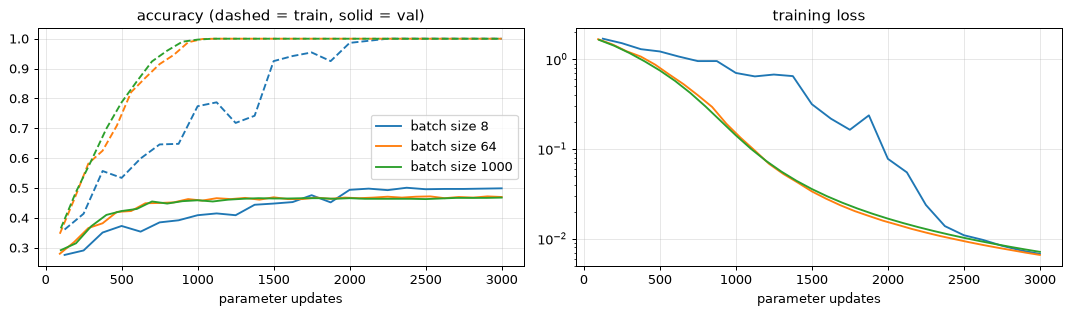

,epochs,examples processed,final train loss,train acc,val acc,val loss
batch size,,,,,,
8,24.0,24000.0,0.0068,1.0,0.499,2.5979
64,192.0,192000.0,0.0066,1.0,0.470,2.9491
1000,3000.0,3000000.0,0.0071,1.0,0.468,2.9949


In [57]:
# Plot against the number of parameter updates, and a summary table
fig, axs = plt.subplots(1, 2, figsize=(12, 3.6))
for i, (bs, h) in enumerate(bs_hists.items()):
    steps = np.array(h["epoch"]) * len(DATA["X_train"]) / bs
    axs[0].plot(steps, h["train_acc"], "--", c=f"C{i}")
    axs[0].plot(steps, h["val_acc"], c=f"C{i}", label=f"batch size {bs}")
    axs[1].plot(steps, h["train_loss"], c=f"C{i}")
axs[0].set_title("accuracy (dashed = train, solid = val)"); axs[0].legend()
axs[1].set_title("training loss"); axs[1].set_yscale("log")
for ax in axs:
    ax.set_xlabel("parameter updates")
plt.tight_layout(); plt.show()
display(pd.DataFrame({bs: {"epochs": h["epoch"][-1], "examples processed": SGD_STEPS * bs,
                           "final train loss": h["train_loss"][-1], "train acc": h["train_acc"][-1],
                           "val acc": h["val_acc"][-1], "val loss": h["val_loss"][-1]}
                      for bs, h in bs_hists.items()}).T.rename_axis("batch size").round(4))

In [58]:
# Tests for 7.1 (implementation)
assert set(bs_hists) == set(BATCH_SIZES)
assert bs_hists[8]["epoch"][-1] == 24 and bs_hists[1000]["epoch"][-1] == 3000, "wrong number of epochs"
assert all(not np.isnan(h["val_acc"][-1]) for h in bs_hists.values()), "pass the validation set"
print("7.1 tests passed")
# Sanity check (results)
expect(all(h["train_acc"][-1] > 0.99 for h in bs_hists.values()), "every run reaches 100% training accuracy")

7.1 tests passed
✓ every run reaches 100% training accuracy


> All three runs reach 100% training accuracy, so they all *interpolate* the training labels, but not at the same point, and not necessarily at a minimum of the training loss.
> (a) Which batch size generalizes best, and why?
> (b) Why compare at an equal number of updates instead of epochs, and what does this design still not control for?

**(a)** Batch size 8 generalizes best: validation accuracy 0.499 against 0.470 (64) and 0.468 (1000), and validation loss 2.60 against 2.95 and 2.99, while all three end with almost the same training loss (about 0.007). A mini-batch gradient is the full gradient plus noise whose variance grows as the batch gets smaller (and as the learning rate gets larger). In a sharp minimum this noise keeps kicking the weights out, so SGD with small batches tends to settle in wide, flat regions, where the loss changes little when the weights move. Those solutions generalize better, because a small shift between the training and test distributions changes their loss little. This is the implicit regularization of SGD: the optimizer chooses among the many solutions that fit the training set, and noisy small-batch steps prefer the flat ones (one can show that SGD approximately minimizes the loss plus a term proportional to $\frac{\eta}{B}$ times the squared norm of the mini-batch gradients). The noise is visible in the curves: the batch-8 training loss is bumpy and its train accuracy jumps around before reaching 100%.

**(b)** Each update moves the weights by one step of the same learning rate, so an equal number of updates gives every run the same optimization "distance". With an equal number of epochs, the full-batch run would make only 24 updates and would not even fit the training set, so we would be comparing a finished training with an unfinished one. What this design does not control: the full-batch run processed 125 times more examples (3,000,000 against 24,000) and saw every example 3000 times instead of 24, so it had far more compute and far more chances to memorize. The learning rate is the same 0.1 for every batch size, but the noise scale depends on $\eta/B$, and in practice a larger batch is trained with a larger learning rate (linear scaling rule), so the large-batch runs may just have an untuned learning rate. Finally, there is one seed per setting, and a 3-point gap is close to the run-to-run spread we saw between ensemble members (0.47 to 0.49). So the experiment is consistent with "small batches generalize better at equal steps and equal learning rate", but it cannot separate the effect of gradient noise from the effects of fewer passes over the data and an untuned learning rate. That would need several seeds and a learning rate tuned for each batch size.

### 7.2 Double descent

We reproduce the *Double descent* slide (MNIST-1D with label noise). Setting: **3000** training examples with
**20% label noise** (labels of the training set only), networks with **one** hidden layer of width $w$, trained with
full-batch Adam (`lr=1e-2`) for 3000 steps without any regularization — long enough for the large networks to reach
zero training error.

For each width in `WIDTHS` the network trains from the same seed, and the table records the classification error ($1 -$ accuracy) on the noisy training set and on the clean validation set. The test set is not used. *(≈ 2–3 min)*

In [59]:
DD_DATA = load_mnist1d(n_train=3000, label_noise=0.2)
DD_TRAIN = dict(epochs=3000, lr=1e-2, batch_size=None, eval_every=3000)
WIDTHS = [4, 8, 16, 24, 32, 48, 64, 96, 128, 256, 512]
dd_rows = []
for w in WIDTHS:
    seed_everything(SEED)
    model = make_mlp(40, 10, hidden=w, depth=1)
    train_model(model, DD_DATA["X_train"], DD_DATA["y_train"], **DD_TRAIN)
    _, train_acc = evaluate(model, DD_DATA["X_train"], DD_DATA["y_train"], F.cross_entropy)
    _, val_acc = evaluate(model, DD_DATA["X_val"], DD_DATA["y_val"], F.cross_entropy)
    dd_rows.append(dict(width=w, params=sum(p.numel() for p in model.parameters()),
                        train_err=1 - train_acc, val_err=1 - val_acc))

dd = pd.DataFrame(dd_rows).set_index("width")
display(dd.round(3))

,params,train_err,val_err
width,,,
4,214,0.657,0.629
8,418,0.586,0.616
16,826,0.489,0.540
24,1234,0.403,0.550
32,1642,0.357,0.608
48,2458,0.239,0.662
64,3274,0.040,0.637
96,4906,0.000,0.678
128,6538,0.000,0.627


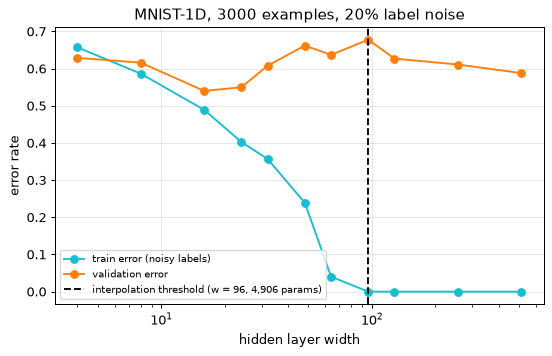

In [60]:
# The double-descent plot
_fits = dd.index[dd["train_err"] < 0.005]
interp_w = _fits[0] if len(_fits) else dd.index[-1]        # first width that interpolates the (noisy) training set
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(dd.index, dd["train_err"], "o-", c="C9", label="train error (noisy labels)")
ax.plot(dd.index, dd["val_err"], "o-", c="C1", label="validation error")
ax.axvline(interp_w, c="k", ls="--", label=f"interpolation threshold (w = {interp_w}, {dd.loc[interp_w, 'params']:,} params)")
ax.set_xscale("log"); ax.set_xlabel("hidden layer width"); ax.set_ylabel("error rate")
ax.set_title("MNIST-1D, 3000 examples, 20% label noise"); ax.legend(fontsize=8); plt.show()

In [61]:
# Tests for 7.2 (implementation)
assert list(dd.index) == WIDTHS and {"params", "train_err", "val_err"} <= set(dd.columns)
assert dd.loc[512, "params"] == 40 * 512 + 512 + 512 * 10 + 10
assert ((dd[["train_err", "val_err"]] >= 0) & (dd[["train_err", "val_err"]] <= 1)).all().all(), "errors must be rates in [0, 1]"
print("7.2 tests passed")
# Sanity checks (results)
expect(dd.loc[512, "train_err"] < 0.005, "the widest network interpolates the noisy training set")
expect(dd.loc[4, "train_err"] > 0.4, "the narrowest network cannot fit the training set")

7.2 tests passed
✓ the widest network interpolates the noisy training set
✓ the narrowest network cannot fit the training set


> (a) What are the three regimes of the validation-error curve, where is the interpolation threshold, and how does the parameter count there compare with the number of training examples?
> (b) Why does the validation error peak where the model can just fit the training set, and fall again for larger models?
> (c) Why does label noise make the peak more visible, and what does this say about choosing capacity at the bottom of the U-shaped curve?

**(a)** *Under-parameterized regime* (width 4 to 16): both errors fall, and the validation error reaches its first minimum, 0.540, at width 16 (826 parameters), while the training error is still 0.49. *Critical regime* (width 24 to 96): the training error falls quickly (0.40, 0.36, 0.24, 0.04, 0) and the validation error rises, up to its peak of 0.678 at width 96. Width 96 is the interpolation threshold, the first width with zero training error. It has 4906 parameters for 3000 examples, about 1.6 parameters per example, so the parameter count is of the same order as the number of examples. To fit the 600 random labels the network has to memorize them one by one, which needs roughly one "unit of capacity" per example. *Over-parameterized regime* (width 128 to 512): the training error stays at 0, and the validation error falls again, 0.627, 0.611, 0.588. In our run this second descent does not yet go below the first minimum (0.540) within the widths we tried. It is still falling at width 512 and would need wider networks to get there.

**(b)** At the threshold the network has just enough capacity to fit all 3000 labels, so there are very few weight settings that do so, and to reach every noisy label it must bend sharply around each one. That means large weights, a very irregular function, and high variance: a small change in the training set would give a very different function. This is the same effect as the 14 regions for 15 points in Section 1. Past the threshold, many different weight settings interpolate the training set, and the optimizer, started from small weights, finds one of the smoother ones, close to the minimum-norm interpolant. The extra capacity lets each noisy point be fitted by a small local bump while the rest of the function stays smooth, which is the slide's "adding more capacity … smoother functions". (In Section 1 the same thing happened with `pinv`: the variance fell from 2.37 at 14 regions to 0.16 at 50.)

**(c)** With clean labels, a function that fits all training points can still be close to the true function, so being forced to interpolate does little harm and the peak is small. With 20% random labels, interpolating means memorizing 600 points that contradict the structure of the data, and near the threshold the model can only do that with the most irregular function, so the peak is large. The classical advice finds the bottom of the U in the under-parameterized regime (width 16 here), but that is only a *local* minimum. Making the model much larger can be as good or better, and the worst choice is right at the threshold, where "a bit more capacity" makes things worse. So capacity should be searched on both sides of the threshold on the validation set, and regularization (L2, early stopping, more data) can also flatten the peak.

---
## Leaderboard

Every method was applied to the same problem (MNIST-1D, 1000 training examples, same architecture and training budget). The methods are ranked by validation accuracy, which is what every choice above was based on. The test accuracy appears here once, as the final estimate for each selected model, and is not used to choose anything.

,val_acc,val_loss,test_acc,test_loss
data augmentation,0.642,1.113,0.633,1.184
dropout (keep=0.5),0.537,1.847,0.548,1.727
L2 (λ=0.001),0.514,2.029,0.507,1.900
ensemble (10 seeds),0.494,2.838,0.516,2.679
label smoothing (ε=0.2),0.480,1.637,0.474,1.608
early stopping,0.465,2.356,0.475,2.241
bagging (10 bootstraps),0.461,2.347,0.491,2.163
baseline,0.458,4.083,0.477,3.848


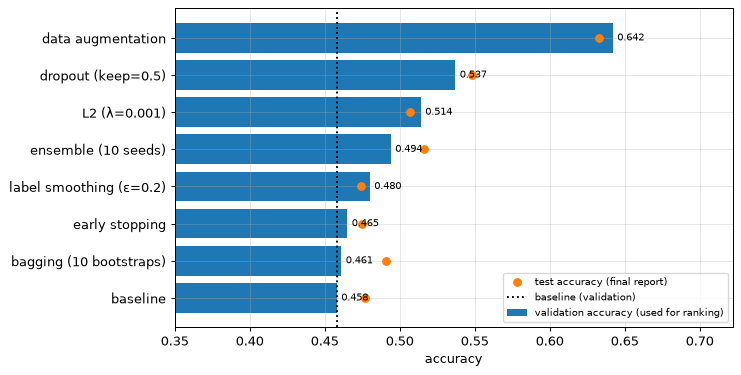

In [62]:
board = show_results()
display(board)
fig, ax = plt.subplots(figsize=(8, 0.45 * len(board) + 1))
names = board.index[::-1]
ax.barh(names, board["val_acc"][::-1], color="C0", label="validation accuracy (used for ranking)")
ax.scatter(board["test_acc"][::-1], names, c="C1", zorder=3, label="test accuracy (final report)")
ax.axvline(RESULTS["baseline"]["val_acc"], c="k", ls=":", label="baseline (validation)")
for i, v in enumerate(board["val_acc"][::-1]):
    ax.text(v + 0.003, i, f"{v:.3f}", va="center", fontsize=8)
ax.set_xlabel("accuracy"); ax.set_xlim(0.35, board[["val_acc", "test_acc"]].values.max() + 0.08)
ax.legend(fontsize=8, loc="lower right"); plt.show()

---
## 8. Combining everything on 500 examples

The training set is now even smaller: 500 examples (`CH_DATA`). The goal is the best classifier I can build by combining the techniques above, or anything else such as a different architecture, without extra data. All choices are made on the validation set, the final test cell runs once at the end, and the whole section trains in under about 5 minutes on a CPU. For reference, the unregularized MLP gets about 0.36 on validation.

In [63]:
CH_DATA = load_mnist1d(n_train=500, seed=1)
seed_everything(SEED)
ch_baseline = make_mlp(**MLP)
train_model(ch_baseline, CH_DATA["X_train"], CH_DATA["y_train"], **CLF)
print("challenge baseline: val acc %.3f" % evaluate(ch_baseline, CH_DATA["X_val"], CH_DATA["y_val"], F.cross_entropy)[1])

challenge baseline: val acc 0.359


In [64]:
# A small 1D CNN: convolution shares weights across positions, so a pattern learned at one position
# is recognised at every other position (the architectural version of the shift augmentation).
def make_cnn(channels=32, keep_prob=1.0):
    return nn.Sequential(
        nn.Unflatten(1, (1, 40)),
        nn.Conv1d(1, channels, 5, padding=2, padding_mode="circular"), nn.ReLU(),
        nn.Conv1d(channels, channels, 5, stride=2, padding=2, padding_mode="circular"), nn.ReLU(),
        nn.Conv1d(channels, channels, 5, stride=2, padding=2, padding_mode="circular"), nn.ReLU(),
        nn.Flatten(), InvertedDropout(keep_prob), nn.Linear(channels * 10, 10))


CANDIDATES = {
    "MLP + augmentation":               lambda: make_mlp(**MLP),
    "MLP + augmentation + dropout 0.8": lambda: make_mlp(**MLP, dropout=lambda: InvertedDropout(0.8)),
    "CNN + augmentation":               lambda: make_cnn(),
    "CNN + augmentation + dropout 0.8": lambda: make_cnn(keep_prob=0.8),
}

t_start = time.time()
cand_val = {}
for name, build in CANDIDATES.items():
    seed_everything(SEED)
    model = build()
    h = train_model(model, CH_DATA["X_train"], CH_DATA["y_train"], **CLF, batch_transform=augment_mnist1d,
                    penalty_fn=l2_penalty, lam=1e-4, X_val=CH_DATA["X_val"], y_val=CH_DATA["y_val"])
    cand_val[name] = h["val_acc"][-1]
    print(f"{name:35s} val acc {cand_val[name]:.3f}   ({h['time']:.0f} s)")

best_name = max(cand_val, key=cand_val.get)
print("chosen on validation:", best_name)

# Ensemble of K members of the chosen recipe, each with its own seed (= its own init and batch order).
K_CH = 5
members = []
for k in range(K_CH):
    seed_everything(200 + k)
    model = CANDIDATES[best_name]()
    train_model(model, CH_DATA["X_train"], CH_DATA["y_train"], **CLF, batch_transform=augment_mnist1d,
                penalty_fn=l2_penalty, lam=1e-4)
    members.append(model)
    print(f"member {k}: val acc {evaluate(model, CH_DATA['X_val'], CH_DATA['y_val'], F.cross_entropy)[1]:.3f}")

challenge_model = EnsembleModel(members)
print(f"ensemble of {K_CH}: val acc {evaluate(challenge_model, CH_DATA['X_val'], CH_DATA['y_val'], F.cross_entropy)[1]:.3f}")
print(f"total time of this part: {time.time() - t_start:.0f} s")

MLP + augmentation                  val acc 0.532   (3 s)


MLP + augmentation + dropout 0.8    val acc 0.550   (4 s)


CNN + augmentation                  val acc 0.799   (9 s)


CNN + augmentation + dropout 0.8    val acc 0.812   (10 s)
chosen on validation: CNN + augmentation + dropout 0.8


member 0: val acc 0.819


member 1: val acc 0.829


member 2: val acc 0.805


member 3: val acc 0.826


member 4: val acc 0.823
ensemble of 5: val acc 0.842
total time of this part: 61 s


In [65]:
# Final evaluation — run once at the end
ch_val = evaluate(challenge_model, CH_DATA["X_val"], CH_DATA["y_val"], F.cross_entropy)
ch_test = evaluate(challenge_model, CH_DATA["X_test"], CH_DATA["y_test"], F.cross_entropy)
print(f"challenge model: val acc {ch_val[1]:.3f} | TEST acc {ch_test[1]:.3f} | test NLL {ch_test[0]:.3f}")

challenge model: val acc 0.842 | TEST acc 0.838 | test NLL 0.454


> Which techniques did I combine and why, what did not help, and where does each technique sit in the lecture's *Overview of regularization techniques* diagram (make the function smoother, increase data, combine multiple models, find wider minima)?

I combined five techniques, all chosen on the validation set. A small 1D CNN instead of the MLP, because the digits are shifted and convolution shares weights across positions. Shift/scale/noise augmentation from 6.1, for the same reason. A small L2 penalty ($\lambda = 10^{-4}$). Dropout (keep 0.8) before the last layer. Finally, an ensemble of 5 seeds. Validation accuracy: MLP + augmentation 0.532, plus dropout 0.550, CNN + augmentation 0.799, plus dropout 0.812. The five CNN members scored 0.805 to 0.829, the ensemble 0.842, and the test accuracy is 0.838.

What did not help much: regularizing the MLP. Even with augmentation and dropout it stayed around 0.55, because no penalty teaches it shift invariance. Dropout on the CNN added only about 1 point.

Placement in the diagram: the CNN and L2 *make the function smoother* (a restricted, simpler function class); augmentation *increases the data*; the ensemble and dropout *combine multiple models*; Adam with mini-batches of 50 helps *find wider minima*. On this dataset, shift invariance mattered by far the most (CNN plus augmentation took validation from 0.55 to 0.80). The ensemble added 2 to 3 points.